# AN8 — Validated Metrics and Curated Reporting Tables

**Execution status: INITIAL AND EXTENDED SQL INVESTIGATIONS EXECUTED; 17 CSV RESULT SETS REVIEWED AND VISUALIZED; INTEGRATED DIAGNOSTICS IN SECTIONS 19–20 EXECUTED WITH SAVED OUTPUTS.** The saved SQL execution evidence remains in this notebook. Sections 17–20 use retained CSV exports and in-memory DataFrames; they do not reconnect to PostgreSQL or rerun SQL.

The executed scope includes AN8.01–AN8.04, AN8.10–AN8.12, AN8.20, and AN8.30–AN8.36. The local export verification reported 15 query records, 17 CSV result files, 37,584 exported result rows, six passing export gates, and zero export errors. The CSV files remain local and Git-ignored; this notebook contains reproducible loading, validation, interpretation, and visualization code rather than the private/local data extracts.

**Integrated diagnostics:** Sections 19.01–19.07 have saved execution counts 37–43 and retained outputs. Section 20 is the interpretive evidence-to-decision register. The numerical findings below are based on those saved outputs; they are not a new database execution in this documentation update.

## Analytical architecture

1. Run canonical read-only SQL extracts with explicit validation gates.
2. Retain complete result sets as local CSV files with a non-sensitive manifest under `outputs/an8/extracts/`.
3. Validate and inspect each CSV independently against the manifest.
4. Generate visualizations and integrated diagnostics from saved CSV files only; no SQL execution or database connection is used in Sections 17–20.
5. Interpret results in educational terms while retaining grain, denominator, time-window, missingness, and scenario controls.
6. Only after separate explicit approval, build validated reporting outputs and a Power BI semantic model.

The validated cohort grain is **student–presentation**, identified by `code_module` + `code_presentation` + `id_student`. Assessment-opportunity and source-activity-row grains are different and must not be described as unique students. `final_result` is retrospective context, not an approved predictive feature, causal measure, KPI, threshold, or composite score. Curated database objects remain a separate persistent change requiring explicit approval.

## 0. Environment and helper imports

The helper imports completed successfully. The project root was located, and the AN8 runner imported without error. This cell does not connect to PostgreSQL.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Locate the repository root from the current Jupyter directory.
PROJECT_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "scripts" / "run_an8.py").is_file()
        and (parent / "src" / "analytics" / "db.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the OULAD repository root. "
        "Start Jupyter from the repository or one of its subdirectories."
    )

# Make the repository root available to Python imports.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.run_an8 import preflight, run_one, export_results

AN8_EXPORT_DIR = PROJECT_ROOT / "outputs" / "an8" / "extracts"
query_results = {}

print("Project root:", PROJECT_ROOT)
print("AN8 runner import: PASS")

Project root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics
AN8 runner import: PASS


## 1. Database identity and read-only preflight

**Execution result: PASS.** The saved preflight output confirms database `oulad_analytics`, user `postgres`, schema `public`, PostgreSQL 18.6, `transaction_read_only=on`, and `default_transaction_read_only=on`. The configured statement and lock timeouts were `2min` and `5s`. This establishes the intended read-only connection context for the executed batch; it does not validate queries that have not yet run.

In [2]:
preflight_result = preflight()


AN8 — read-only database preflight
  database_name database_user current_schema server_version transaction_read_only default_transaction_read_only statement_timeout lock_timeout
oulad_analytics      postgres         public           18.6                    on                            on              2min           5s
database_name: PASS
transaction_read_only: PASS
default_transaction_read_only: PASS


## 2. AN8.01 — Source relation inventory

**Execution result: PASS.** All seven expected STAGING relations were found. The query reads PostgreSQL catalog statistics rather than counting every row. Its `estimated_rows` values are planner estimates, not exact table counts. In particular, the estimate of zero for `staging.courses` does not establish that the table is empty. The `last_analyze` and `last_autoanalyze` fields were NULL for all seven relations, so the estimates should not be used as exact population figures.

In [3]:
an801 = run_one("AN8.01")
query_results["AN8.01"] = an801
an801["data"]


AN8.01 — source readiness gate
all_expected_relations_returned: PASS
all_expected_relations_exist: PASS
AN8.01: 0.065 s; 1 result set(s); 7 displayed rows; no truncation


,source_relation,relation_exists,estimated_rows,last_analyze,last_autoanalyze
0,staging.assessments,True,206,None,None
1,staging.courses,True,0,None,None
2,staging.student_assessment,True,173912,None,None
3,staging.student_info,True,32593,None,None
4,staging.student_registration,True,32593,None,None
5,staging.student_vle,True,10654140,None,None
6,staging.vle,True,6364,None,None


## 3. AN8.02 — Student-presentation grain and key-set gate

**Execution result: PASS — all six checks.** Both `staging.student_info` and `staging.student_registration` returned 32,593 rows and 32,593 distinct composite keys. Each source had zero duplicate key groups and zero rows with NULL key components. The bidirectional key-set comparison returned zero differences.

The validated join key is `code_module + code_presentation + id_student`. The analytical grain is therefore **one student–presentation**, not one person: a student may appear in more than one module or presentation. This gate validates the relationship between these two sources only; it does not establish key integrity for every other STAGING relation.

In [4]:
an802 = run_one("AN8.02")
query_results["AN8.02"] = an802
an802["data"]


AN8.02 — student-presentation grain gate
    check_type            check_name  source_rows  distinct_keys  duplicate_key_groups  null_key_rows  key_count
KEY_DIFFERENCE INFO_NOT_REGISTRATION          NaN            NaN                   NaN            NaN        0.0
KEY_DIFFERENCE REGISTRATION_NOT_INFO          NaN            NaN                   NaN            NaN        0.0
  SOURCE_GRAIN          student_info      32593.0        32593.0                   0.0            0.0        NaN
  SOURCE_GRAIN  student_registration      32593.0        32593.0                   0.0            0.0        NaN
no_duplicate_student_info_keys: PASS
no_duplicate_registration_keys: PASS
student_info_rows_equal_distinct_keys: PASS
registration_rows_equal_distinct_keys: PASS
no_null_key_rows: PASS
no_key_set_differences: PASS
AN8.02: 0.659 s; 1 result set(s); 4 displayed rows; no truncation


,check_type,check_name,source_rows,distinct_keys,duplicate_key_groups,null_key_rows,key_count
0,KEY_DIFFERENCE,INFO_NOT_REGISTRATION,NaN,NaN,NaN,NaN,0.0
1,KEY_DIFFERENCE,REGISTRATION_NOT_INFO,NaN,NaN,NaN,NaN,0.0
2,SOURCE_GRAIN,student_info,32593.0,32593.0,0.0,0.0,NaN
3,SOURCE_GRAIN,student_registration,32593.0,32593.0,0.0,0.0,NaN


## 4. AN8.03 — Outcome denominator profile

**Execution result: PASS.** The four retrospective `final_result` categories reconcile to 32,593 student–presentation rows, and all 32,593 rows have a matching registration record. The result profile is suitable for describing the validated cohort at student–presentation grain.

The `distinct_student_ids_in_category` field counts unique student IDs separately within each outcome category. These category-specific counts are not mutually exclusive across presentations and must not be added to infer the number of unique people. Because `final_result` is a retrospective outcome, it must not be treated as information available during a student's active study period or as evidence of causation or predictive performance.

In [18]:
an803 = run_one("AN8.03")
query_results["AN8.03"] = an803
an803["data"]

\nAN8.03 — outcome denominator reconciliation
outcome_denominator_matches_student_info: PASS
registration_matches_equal_validated_cohort: PASS
AN8.03: 0.268 s; 1 result set(s); 4 displayed rows; no truncation


,final_result,student_presentation_rows,registration_matched_rows,distinct_student_ids_in_category
0,Distinction,3024,3024,2903
1,Fail,7052,7052,6810
2,Pass,12361,12361,11881
3,Withdrawn,10156,10156,9155


### Outcome distribution — student–presentation records

The table above establishes the category counts and denominator reconciliation. The chart below expresses the same validated counts as both record totals and shares of the 32,593 student–presentation records. It is generated from the saved AN8.03 result in memory; it does not issue another SQL query or reconnect to PostgreSQL.

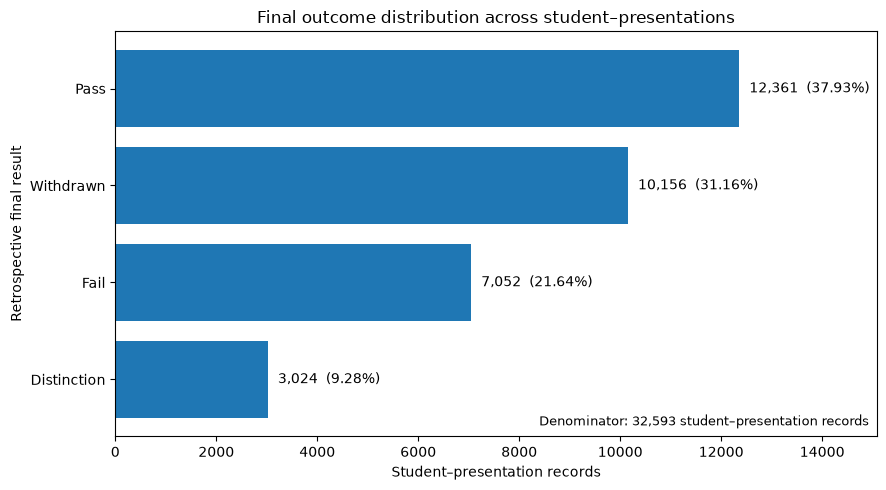

In [6]:
import matplotlib.pyplot as plt

outcome_plot = an803["data"][[
    "final_result",
    "student_presentation_rows",
    "registration_matched_rows",
]].copy()

outcome_plot["share_pct"] = (
    outcome_plot["student_presentation_rows"]
    / outcome_plot["student_presentation_rows"].sum()
    * 100
)
outcome_plot = outcome_plot.sort_values(
    "student_presentation_rows", ascending=True
)

denominator = int(outcome_plot["student_presentation_rows"].sum())
assert denominator == 32593
assert (
    outcome_plot["student_presentation_rows"]
    == outcome_plot["registration_matched_rows"]
).all()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(
    outcome_plot["final_result"],
    outcome_plot["student_presentation_rows"],
)
ax.set_title("Final outcome distribution across student–presentations")
ax.set_xlabel("Student–presentation records")
ax.set_ylabel("Retrospective final result")
ax.set_xlim(0, outcome_plot["student_presentation_rows"].max() * 1.22)

for bar, count, share in zip(
    bars,
    outcome_plot["student_presentation_rows"],
    outcome_plot["share_pct"],
):
    ax.text(
        bar.get_width() + denominator * 0.006,
        bar.get_y() + bar.get_height() / 2,
        f"{int(count):,}  ({share:.2f}%)",
        va="center",
    )

ax.text(
    0.99, 0.02,
    f"Denominator: {denominator:,} student–presentation records",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)
fig.tight_layout()
plt.show()

### Interpretation of the outcome distribution

The distribution is led by **Pass** (12,361 records; 37.93%), followed by **Withdrawn** (10,156; 31.16%), **Fail** (7,052; 21.64%), and **Distinction** (3,024; 9.28%). The chart makes the relative size of these four categories easier to compare while preserving the exact student–presentation denominator.

The withdrawal category represents nearly one third of the records, so it should remain visible in later descriptive analysis rather than being silently combined with failure or excluded from the cohort. This distribution alone does not explain why students withdrew, establish when withdrawal occurred, or measure engagement. Those questions require the registration-timing and activity evidence planned in subsequent AN8 sections.

The denominator is student–presentation records, not unique individuals. The chart is a retrospective cohort description and must not be interpreted as a causal comparison, a live-risk indicator, or a model-performance result.

## 5. AN8.04 — Course and assessment context

AN8.04 returns **two result sets**. The runner checks truncation independently for each result set. Due dates and weights do not establish score or feedback availability.

In [5]:
an804 = run_one("AN8.04")
query_results["AN8.04"] = an804
for item in an804["result_sets"]:
    display(item["data"])


AN8.04 — course and assessment context gate
course_context_nonempty: PASS
course_keys_non_null: PASS
course_keys_unique: PASS
course_lengths_non_null: PASS
assessment_context_keys_unique: PASS
assessment_context_covers_course_keys: PASS
AN8.04: 0.037 s; 2 result set(s); 44 displayed rows; no truncation


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013B,240
3,BBB,2013J,268
4,BBB,2014B,234
5,BBB,2014J,262
6,CCC,2014B,241
7,CCC,2014J,269
8,DDD,2013B,240
9,DDD,2013J,261


,code_module,code_presentation,assessment_count,missing_due_dates,total_weight
0,AAA,2013J,6,1,200
1,AAA,2014J,6,1,200
2,BBB,2013B,12,1,200
3,BBB,2013J,12,1,200
4,BBB,2014B,12,1,200
5,BBB,2014J,6,1,200
6,CCC,2014B,10,2,300
7,CCC,2014J,10,2,300
8,DDD,2013B,14,0,200.0
9,DDD,2013J,7,0,200.0


## 6. AN8.10–AN8.12 — Lightweight descriptive context

Run these only after the grain gate passes. Each query has its own result set and must be reviewed before the activity extract. These are descriptive context, not approved KPIs.

In [19]:
for query_id in ("AN8.10", "AN8.11", "AN8.12"):
    query_results[query_id] = run_one(query_id)
    print(query_id)
    display(query_results[query_id]["data"])

AN8.10: 0.026 s; 1 result set(s); 4 displayed rows; no truncation
AN8.10


,registration_timing,registrations
0,AFTER_START,234
1,BEFORE_START,32312
2,MISSING,45
3,ON_START,2


AN8.11: 0.058 s; 1 result set(s); 6 displayed rows; no truncation
AN8.11


,final_result,unregistration_state,student_presentations
0,Distinction,NO_UNREGISTRATION_DATE,3024
1,Fail,HAS_UNREGISTRATION_DATE,9
2,Fail,NO_UNREGISTRATION_DATE,7043
3,Pass,NO_UNREGISTRATION_DATE,12361
4,Withdrawn,HAS_UNREGISTRATION_DATE,10063
5,Withdrawn,NO_UNREGISTRATION_DATE,93


AN8.12: 0.085 s; 1 result set(s); 3 displayed rows; no truncation
AN8.12


,score_state,student_assessment_rows
0,NONZERO_SCORE,173410
1,NULL_SCORE,173
2,OBSERVED_ZERO,329


**Execution status: EXECUTED AND EXPORTED.**

In [9]:
activity_extract = run_one("AN8.20")
query_results["AN8.20"] = activity_extract
activity_frame = activity_extract["data"]
print(activity_frame.shape)
display(activity_frame.head())


AN8.20 — student-presentation extract gate
row_count_matches_validated_cohort: PASS
unique_student_presentation_key: PASS
non_null_student_presentation_key: PASS
AN8.20: 85.582 s; 1 result set(s); 32593 displayed rows; no truncation
(32593, 37)


,code_module,code_presentation,id_student,date_registration,course_length,exposure_start,post_registration_exposure_days,all_observed_activity_rows,all_observed_recorded_clicks,pre_course_activity_rows,...,matched_registered_recorded_clicks,unmatched_recorded_clicks,all_source_in_course_activity_rows,all_source_pre_course_activity_rows,all_source_post_course_activity_rows,all_source_no_course_window_activity_rows,all_source_pre_course_recorded_clicks,all_source_in_course_recorded_clicks,all_source_post_course_recorded_clicks,all_source_no_course_window_recorded_clicks
0,AAA,2013J,11391,-159.0,268,0.0,269.0,196,934,11,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
1,AAA,2013J,28400,-53.0,268,0.0,269.0,430,1435,55,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
2,AAA,2013J,30268,-92.0,268,0.0,269.0,76,281,34,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
3,AAA,2013J,31604,-52.0,268,0.0,269.0,663,2158,38,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
4,AAA,2013J,32885,-176.0,268,0.0,269.0,352,1034,66,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0


## 11. Curated reporting tables — approval gate

The intended downstream design is to load the validated retained extracts into a small set of persistent, documented reporting tables (for example, a student-presentation activity fact and course/assessment dimensions), then build all charts and Power BI datasets from those tables.

**No table, view, materialized view, index, schema, or DDL is created here.** Before deployment, the project owner must review and explicitly approve:
- table names, schemas, columns, keys, and data types;
- CSV-to-table load method and reconciliation checks;
- refresh/replacement policy and provenance manifest;
- retention, access, and privacy controls;
- exact row/key/count/denominator acceptance criteria.

After approval, prepare a separate DDL/load work order. It must load the already validated extracts, not rescan `staging.student_vle` to recreate chart inputs.

## 14. AN8.30–AN8.36 — Extended analytical investigation

The extended SQL investigations have been executed and their result sets were included in the locally verified AN8 export. Their scopes are:

| Query | Scope | Result |
|---|---|---:|
| AN8.30 | R0/R1/R2 scenario totals and source-quality/reference-integrity diagnostics | 2 result sets |
| AN8.31 | Zero-inclusive activity-row, click, active-day, and resource-breadth distributions | 1 result set |
| AN8.32 | Registration timing and available exposure days | 1 result set |
| AN8.33 | Candidate metric definitions and approval status | 1 result set |
| AN8.34 | Activity distributions by outcome within each presentation | 1 result set |
| AN8.35 | Assessment participation and score-state coverage | 1 result set |
| AN8.36 | Outcome segments by student-profile dimensions | 1 result set |

AN8.30 complements rather than replaces AN5 scenario sensitivity. AN8.34 uses final_result only as retrospective descriptive grouping. AN8.35 separates no submission from recorded NULL and observed-zero score states. AN8.36 is descriptive and is not a fairness assessment.

The complete CSV outputs are reviewed in the Python-only section added at the end of this notebook. That section validates each file against the manifest and visualizes each result set independently of PostgreSQL.

In [6]:
an830 = run_one("AN8.30")
query_results["AN8.30"] = an830
for item in an830["result_sets"]:
    display(item["data"])

AN8.30: 220.715 s; 2 result set(s); 5 displayed rows; no truncation


,scenario,activity_rows,recorded_clicks,r0_rows,repeated_five_key_groups,excess_rows_over_five_key,multi_click_value_groups,maximum_five_key_group_size,nonpositive_click_rows,null_click_rows,min_clicks,max_clicks,pre_course_rows
0,R0,10655280,39605099,10655280,1614505,2195960,1179074,10,0,0,1,6977,688988
1,R1,9868110,38343063,10655280,1614505,2195960,1179074,10,0,0,1,6977,688988
2,R2,8459320,34402738,10655280,1614505,2195960,1179074,10,0,0,1,6977,688988


,registration_state,course_state,resource_state,temporal_state,source_rows,recorded_clicks
0,REGISTRATION_MATCH,COURSE_MATCH,VLE_RESOURCE_MATCH,IN_COURSE,9966292,37457152
1,REGISTRATION_MATCH,COURSE_MATCH,VLE_RESOURCE_MATCH,PRE_COURSE,688988,2147947


### AN8.31 — Zero-inclusive registered activity distributions

This is a separate high-cost SQL aggregation. The registered student–presentation population remains the denominator, including zero-activity registrations. Source-row and click measures remain sensitive to repeated student_vle records; active days and resource breadth are distinct-value measures.

In [7]:
an831 = run_one("AN8.31")
query_results["AN8.31"] = an831
display(an831["data"])

AN8.31: 66.266 s; 1 result set(s); 88 displayed rows; no truncation


,code_module,code_presentation,metric,registered_denominator,zero_value_count,pct_zero,mean_value,p25,median,p75,p90,max_value
0,AAA,2013J,ACTIVE_DAYS,383,7,1.83,84.74,38.5,76,119.5,169,261
1,AAA,2013J,ACTIVITY_ROWS,383,7,1.83,444.22,178,333,585,916.4,2140
2,AAA,2013J,RECORDED_CLICKS,383,7,1.83,1563.63,519.5,1102,1911.5,3480.2,12213
3,AAA,2013J,RESOURCE_BREADTH,383,7,1.83,58.85,42.5,60,78,87,121
4,AAA,2014J,ACTIVE_DAYS,365,13,3.56,77.21,31,64,117,154.6,262
...,...,...,...,...,...,...,...,...,...,...,...,...
83,GGG,2014B,RESOURCE_BREADTH,833,67,8.04,27.68,14,29,41,49,72
84,GGG,2014J,ACTIVE_DAYS,749,60,8.01,32.26,8,27,46,68,240
85,GGG,2014J,ACTIVITY_ROWS,749,60,8.01,146.51,44,125,213,283,1479
86,GGG,2014J,RECORDED_CLICKS,749,60,8.01,500.92,109,407,719,1053.6,7408


### AN8.32 — Registration and exposure profile

Exposure is the inclusive number of course days from the later of registration day and day zero through the course end. Missing registration dates remain unknown; registrations after course end have zero available course exposure. This is opportunity-to-observe, not attendance.

In [8]:
an832 = run_one("AN8.32")
query_results["AN8.32"] = an832
display(an832["data"])

AN8.32: 0.093 s; 1 result set(s); 61 displayed rows; no truncation


,code_module,code_presentation,registration_state,registered_student_presentations,unknown_exposure_count,zero_exposure_count,positive_exposure_count,min_exposure_days,median_exposure_days,p90_exposure_days,max_exposure_days
0,AAA,2013J,AFTER_COURSE_START,4,0,0,4,221.0,256.5,266.1,267.0
1,AAA,2013J,BEFORE_COURSE_START,379,0,0,379,269.0,269,269,269.0
2,AAA,2014J,AFTER_COURSE_START,4,0,0,4,260.0,266,267.7,268.0
3,AAA,2014J,BEFORE_COURSE_START,361,0,0,361,270.0,270,270,270.0
4,BBB,2013B,AFTER_COURSE_START,9,0,0,9,172.0,232,238.2,239.0
...,...,...,...,...,...,...,...,...,...,...,...
56,GGG,2014B,AFTER_COURSE_START,2,0,0,2,236.0,238,239.6,240.0
57,GGG,2014B,BEFORE_COURSE_START,831,0,0,831,242.0,242,242,242.0
58,GGG,2014J,AFTER_COURSE_START,43,0,0,43,251.0,267,268,268.0
59,GGG,2014J,BEFORE_COURSE_START,705,0,0,705,270.0,270,270,270.0


### AN8.33 — Candidate metric register

This query documents operational definitions, grain, denominator, limitations, and approval status. It does not approve a production KPI.

In [10]:
an833 = run_one("AN8.33")
query_results["AN8.33"] = an833
display(an833["data"])

AN8.33: 0.017 s; 1 result set(s); 8 displayed rows; no truncation


,metric_id,operational_definition,grain,denominator,limitation,approval_status
0,assessment_score,score,student-assessment,Observed non-NULL scores,Retrospective; availability time not established,CANDIDATE_NOT_APPROVED
1,final_result,final_result,student-presentation,Validated student_info cohort,Outcome only; never an early predictor,OUTCOME_ONLY
2,in_course_active_days,COUNT(DISTINCT date),student-presentation,All registered keys including zero,Day-level; same-day event order unavailable,CANDIDATE_NOT_APPROVED
3,in_course_activity_presence,has at least one source row in inclusive cours...,student-presentation,All registered keys,No recorded row is not proof of no learning,CANDIDATE_NOT_APPROVED
4,in_course_resource_breadth,COUNT(DISTINCT id_site),student-presentation,All registered keys including zero,Resource breadth is not learning quality,CANDIDATE_NOT_APPROVED
5,post_registration_active_day_rate,active days / available exposure days,student-presentation,Known positive exposure only,Unknown/zero exposure must remain separate,CANDIDATE_NOT_APPROVED
6,recorded_click_volume,SUM(sum_click),student-presentation,All registered keys,Sensitive to repeated source rows; secondary d...,CANDIDATE_NOT_APPROVED
7,registered_student_presentations,COUNT(*),student-presentation,All validated registration keys,Cohort size; not unique people,CANDIDATE_NOT_APPROVED


### AN8.34 — Activity by retrospective outcome and presentation

High-cost descriptive SQL aggregation. Each presentation is reported separately to avoid pooling structurally different cohorts. final_result is used only to describe retrospective associations; it is not an early-warning predictor or causal explanation.

In [11]:
an834 = run_one("AN8.34")
query_results["AN8.34"] = an834
display(an834["data"])

AN8.34: 63.687 s; 1 result set(s); 352 displayed rows; no truncation


,code_module,code_presentation,final_result,metric,student_presentation_denominator,zero_count,pct_zero,mean_value,median,p75,p90
0,AAA,2013J,Distinction,ACTIVE_DAYS,20,0,0.00,166.10,172.5,218,223.7
1,AAA,2013J,Distinction,ACTIVITY_ROWS,20,0,0.00,1009.70,828.5,1594,1758.6
2,AAA,2013J,Distinction,RECORDED_CLICKS,20,0,0.00,3781.10,2702,5247,6951.5
3,AAA,2013J,Distinction,RESOURCE_BREADTH,20,0,0.00,81.85,85.5,96.25,100
4,AAA,2013J,Fail,ACTIVE_DAYS,45,0,0.00,40.64,29,52,96.2
...,...,...,...,...,...,...,...,...,...,...,...
347,GGG,2014J,Pass,RESOURCE_BREADTH,317,0,0.00,39.21,39,46,54.4
348,GGG,2014J,Withdrawn,ACTIVE_DAYS,126,39,30.95,6.37,3,9.5,16
349,GGG,2014J,Withdrawn,ACTIVITY_ROWS,126,39,30.95,25.11,12.5,41.75,60
350,GGG,2014J,Withdrawn,RECORDED_CLICKS,126,39,30.95,67.46,37,96.5,191.5


### AN8.35 — Assessment participation and score-state coverage

The output distinguishes no submission, NULL score, observed zero, and nonzero score. Assessment opportunities repeat across assessments, so assessment-level denominators are not additive counts of unique students.

In [12]:
an835 = run_one("AN8.35")
query_results["AN8.35"] = an835
display(an835["data"])

AN8.35: 3.408 s; 1 result set(s); 156 displayed rows; no truncation


,code_module,code_presentation,assessment_type,score_state,registered_assessment_opportunities,distinct_students,submission_rows,null_score_rows,opportunities_with_observed_zero,opportunities_with_nonzero_score,mean_of_student_scores,median_student_score
0,AAA,2013J,Exam,NO_SUBMISSION,383,383,0,0,0,0,None,None
1,AAA,2013J,TMA,NO_SUBMISSION,282,92,0,0,0,0,None,None
2,AAA,2013J,TMA,NONZERO_SCORE_ONLY,1630,364,1630,0,0,1630,69.47,72
3,AAA,2013J,TMA,NULL_SCORE_ONLY,2,2,2,2,0,0,None,None
4,AAA,2013J,TMA,OBSERVED_ZERO_ONLY,1,1,1,0,1,0,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...
151,GGG,2014J,Exam,NO_SUBMISSION,749,749,0,0,0,0,None,None
152,GGG,2014J,TMA,NO_SUBMISSION,621,263,0,0,0,0,None,None
153,GGG,2014J,TMA,NONZERO_SCORE_ONLY,1621,600,1621,0,0,1621,67.73,70
154,GGG,2014J,TMA,NULL_SCORE_ONLY,2,2,2,2,0,0,None,None


### AN8.36 — Student-profile outcome segments

This profile is grouped by presentation and explicitly retains missing IMD bands. Small segments require review and possible suppression before publication. Results are descriptive associations, not causal effects or a fairness assessment.

In [13]:
an836 = run_one("AN8.36")
query_results["AN8.36"] = an836
display(an836["data"])

AN8.36: 0.252 s; 1 result set(s); 4249 displayed rows; no truncation


,code_module,code_presentation,dimension,segment_value,final_result,student_presentation_rows,pct_within_segment
0,AAA,2013J,AGE_BAND,0-35,Distinction,6,3.35
1,AAA,2013J,AGE_BAND,0-35,Fail,27,15.08
2,AAA,2013J,AGE_BAND,0-35,Pass,120,67.04
3,AAA,2013J,AGE_BAND,0-35,Withdrawn,26,14.53
4,AAA,2013J,AGE_BAND,35-55,Distinction,9,5.06
...,...,...,...,...,...,...,...
4244,GGG,2014J,STUDIED_CREDITS,60,Withdrawn,17,68.00
4245,GGG,2014J,STUDIED_CREDITS,90,Distinction,4,19.05
4246,GGG,2014J,STUDIED_CREDITS,90,Fail,7,33.33
4247,GGG,2014J,STUDIED_CREDITS,90,Pass,5,23.81


The AN8.20 result and the other retained AN8 result sets were exported locally to CSV with a JSON manifest after the runner and export gates passed. This is local file output only; it does not create PostgreSQL objects.

In [25]:
manifest_path = export_results(query_results, AN8_EXPORT_DIR)
manifest_path

AN8 exports and manifest saved to: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics\outputs\an8\extracts


WindowsPath('G:/OULAD-EdTech-Learning-Analytics-starter/OULAD-EdTech-Learning-Analytics/outputs/an8/extracts/an8_execution_manifest.json')

## 9. Python-only reconciliation from retained extracts

All calculations in this section use in-memory results or exported CSVs. No SQL or database connection is issued. Reconcile the course-relative row totals and registered population before creating any visualization.

In [27]:
# Load the persisted AN8.20 extract; this cell performs no database connection.
activity = pd.read_csv(AN8_EXPORT_DIR / "AN8_20_result_01.csv")

# Reuse the validated registration denominator retained by AN8.02.
registration_rows = query_results["AN8.02"]["result_sets"][0]["data"]
registration_denominator = int(
    registration_rows.loc[
        registration_rows["check_type"].eq("SOURCE_GRAIN")
        & registration_rows["check_name"].eq("student_registration"),
        "source_rows",
    ].iloc[0]
)

registered_rows = len(activity)
source_total = int(activity["total_source_activity_rows"].iloc[0])
matched_source_rows = int(activity["matched_registered_activity_rows"].iloc[0])
unmatched_source_rows = int(activity["unmatched_activity_rows"].iloc[0])
source_clicks = float(activity["total_source_recorded_clicks"].iloc[0])
matched_clicks = float(activity["matched_registered_recorded_clicks"].iloc[0])
unmatched_clicks = float(activity["unmatched_recorded_clicks"].iloc[0])

matched_partition_columns = [
    "pre_course_activity_rows",
    "in_course_activity_rows",
    "post_course_activity_rows",
    "no_course_window_activity_rows",
]
source_partition_columns = [
    "all_source_pre_course_activity_rows",
    "all_source_in_course_activity_rows",
    "all_source_post_course_activity_rows",
    "all_source_no_course_window_activity_rows",
]
matched_click_columns = [
    "pre_course_recorded_clicks",
    "in_course_recorded_clicks",
    "post_course_recorded_clicks",
    "no_course_window_recorded_clicks",
]
source_click_columns = [
    "all_source_pre_course_recorded_clicks",
    "all_source_in_course_recorded_clicks",
    "all_source_post_course_recorded_clicks",
    "all_source_no_course_window_recorded_clicks",
]

matched_partition_total = int(activity[matched_partition_columns].sum().sum())
source_partition_total = int(activity[source_partition_columns].iloc[0].sum())
matched_click_partition_total = float(activity[matched_click_columns].sum().sum())
source_click_partition_total = float(activity[source_click_columns].iloc[0].sum())

exposed = activity["post_registration_exposure_days"].notna()
student_presentation_key = ["code_module", "code_presentation", "id_student"]

checks = {
    "row_count_matches_an802_registration_denominator": (
        registered_rows == registration_denominator
    ),
    "non_null_student_presentation_key": (
        not activity[student_presentation_key].isna().any().any()
    ),
    "one_row_per_registered_student_presentation": (
        registered_rows
        == len(activity[student_presentation_key].drop_duplicates())
    ),
    "registered_activity_rows_reconcile": (
        int(activity["all_observed_activity_rows"].sum()) == matched_source_rows
    ),
    "registered_temporal_partition_reconciles": (
        matched_partition_total == matched_source_rows
    ),
    "all_source_temporal_partition_reconciles": (
        source_partition_total == source_total
    ),
    "source_rows_equal_matched_plus_unmatched": (
        source_total == matched_source_rows + unmatched_source_rows
    ),
    "clicks_equal_matched_plus_unmatched": (
        abs(source_clicks - matched_clicks - unmatched_clicks) < 1e-9
    ),
    "registered_click_partition_reconciles": (
        abs(matched_click_partition_total - matched_clicks) < 1e-9
    ),
    "source_click_partition_reconciles": (
        abs(source_click_partition_total - source_clicks) < 1e-9
    ),
    "active_days_are_nonnegative": (
        bool((activity["in_course_active_days"] >= 0).all())
    ),
    "active_days_do_not_exceed_exposure": (
        bool(
            (
                activity.loc[exposed, "post_registration_active_days"] >= 0
            ).all()
            and (
                activity.loc[exposed, "post_registration_active_days"]
                <= activity.loc[exposed, "post_registration_exposure_days"]
            ).all()
        )
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

if not all(checks.values()):
    failed_checks = [name for name, passed in checks.items() if not passed]
    raise RuntimeError(
        "AN8.20 reconciliation failed; stop before visualizations or mart design. "
        f"Failed checks: {failed_checks}"
    )

reconciliation_summary = pd.DataFrame(
    [
        {
            "registered_student_presentations": registered_rows,
            "registration_denominator": registration_denominator,
            "source_activity_rows": source_total,
            "source_recorded_clicks": source_clicks,
            "matched_registered_recorded_clicks": matched_clicks,
            "unmatched_recorded_clicks": unmatched_clicks,
            "matched_registered_activity_rows": matched_source_rows,
            "unmatched_activity_rows": unmatched_source_rows,
            "registered_temporal_partition_rows": matched_partition_total,
            "all_source_temporal_partition_rows": source_partition_total,
        }
    ]
)
display(reconciliation_summary)

row_count_matches_an802_registration_denominator: PASS
non_null_student_presentation_key: PASS
one_row_per_registered_student_presentation: PASS
registered_activity_rows_reconcile: PASS
registered_temporal_partition_reconciles: PASS
all_source_temporal_partition_reconciles: PASS
source_rows_equal_matched_plus_unmatched: PASS
clicks_equal_matched_plus_unmatched: PASS
registered_click_partition_reconciles: PASS
source_click_partition_reconciles: PASS
active_days_are_nonnegative: PASS
active_days_do_not_exceed_exposure: PASS


,registered_student_presentations,registration_denominator,source_activity_rows,source_recorded_clicks,matched_registered_recorded_clicks,unmatched_recorded_clicks,matched_registered_activity_rows,unmatched_activity_rows,registered_temporal_partition_rows,all_source_temporal_partition_rows
0,32593,32593,10655280,39605099.0,39605099.0,0.0,10655280,0,10655280,10655280


## 10. Visualization source contract

Every chart must have its own preceding Markdown explanation. Visualization cells read only the curated reporting tables or retained files under `outputs/an8/`. They must not call `run_one`, `run_batch`, `run_query`, or connect to PostgreSQL.

Illustrative starter below is intentionally Python-only and uses the retained extract.

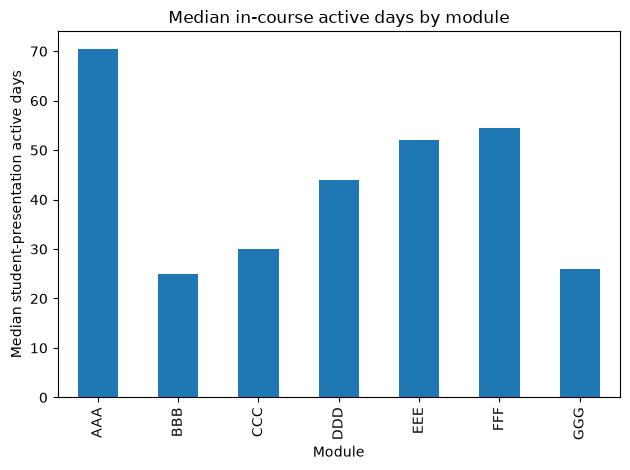

In [28]:
import matplotlib.pyplot as plt

plot_data = activity.groupby("code_module", as_index=False)["in_course_active_days"].median()
ax = plot_data.plot(kind="bar", x="code_module", y="in_course_active_days", legend=False)
ax.set_title("Median in-course active days by module")
ax.set_xlabel("Module")
ax.set_ylabel("Median student-presentation active days")
plt.tight_layout()

## 15. Extended analytical review gate

SQL execution and export completion do not, by themselves, approve a metric. Review the complete CSV result sets, manifest row/column contracts, denominators, zero-inclusive distributions, missing/unknown states, R0/R1/R2 sensitivity, exposure definitions, assessment score states, presentation-specific comparisons, and small-cell limitations.

The owner-reported export verification confirms 15 query records, 17 CSV files, 37,584 exported result rows, six passing export gates, and zero export errors. The following CSV-based review cells independently check the local files against the manifest and create descriptive visualizations. They do not rerun SQL or establish a cleaning rule.

## 16. Current status and next phase gates

**AN8 initial extraction:** executed. Saved outputs document the read-only preflight, source and cohort gates, outcome denominator, course/assessment context, registration timing, withdrawal-date reconciliation, score states, consolidated R0 activity extract, and Python reconciliation.

**AN8 extended analysis:** AN8.30–AN8.36 were executed locally. Their outputs were included in the locally verified export containing 17 CSV result files. The CSV-based review section below is prepared for local execution; its plots are not represented as executed in this repository snapshot.

**AN8 approval status:** no production KPI, cleaning rule, curated reporting table, or Power BI dataset is approved. Metric contracts and denominator decisions remain subject to review. R1 and R2 remain sensitivity scenarios, not approved source transformations.

**Data preservation:** RAW, QUALITY, and STAGING remain unchanged. The executed analytical SQL is read-only. No persistent tables, views, materialized views, indexes, or schemas are created.

AN9 Power BI remains blocked until metrics and the reporting contract are validated. The next analytical work should resolve the cleaning/sensitivity questions and define reproducible derived-data contracts before any persistent reporting model is deployed.

## 17. CSV-based review and visualization — independent of PostgreSQL

This section follows the AN5 review pattern. It reads the already-exported AN8 CSV files and their manifest from `outputs/an8/extracts/`. It does not call the AN8 runner, open a database connection, execute SQL, or load the full `student_vle` table.

Each result set has its own loading/display cell, explanatory Markdown, and visualization cell. Small tables are displayed in full; large extracts are represented by a bounded head/tail preview while all rows remain available for analysis in their DataFrames. Every file is checked against the manifest for its expected row count and column list before use.

After restarting the Jupyter kernel, execute this section starting at the standalone setup cell immediately below (cell 17.00), then continue sequentially through the final inventory cell. The setup locates and validates the local manifest and all six export gates; it imports pandas, matplotlib, and display helpers without importing or calling the database runner. If a file or manifest is absent or differs from the recorded contract, the loader stops rather than silently substituting another source. Earlier database/SQL cells do not need to be rerun.

In [1]:
# 17.00. Standalone CSV-review setup: no PostgreSQL connection and no SQL execution.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Locate the repository from the notebook working directory.
PROJECT_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "outputs" / "an8" / "extracts" / "an8_execution_manifest.json").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate outputs/an8/extracts/an8_execution_manifest.json. "
        "Start Jupyter from the OULAD repository or one of its subdirectories."
    )

AN8_EXPORT_DIR = PROJECT_ROOT / "outputs" / "an8" / "extracts"
AN8_MANIFEST_PATH = AN8_EXPORT_DIR / "an8_execution_manifest.json"

with AN8_MANIFEST_PATH.open("r", encoding="utf-8") as manifest_file:
    an8_manifest = json.load(manifest_file)

required_gates = (
    "read_only_preflight_passed",
    "source_readiness_gate_passed",
    "cohort_grain_gate_passed",
    "outcome_denominator_gate_passed",
    "course_context_gate_passed",
    "activity_extract_gate_passed",
)
failed_gates = [gate for gate in required_gates if an8_manifest.get(gate) is not True]
if failed_gates:
    raise RuntimeError(f"AN8 export manifest has failed or missing gates: {failed_gates}")

expected_query_ids = {
    "AN8.01", "AN8.02", "AN8.03", "AN8.04",
    "AN8.10", "AN8.11", "AN8.12", "AN8.20",
    "AN8.30", "AN8.31", "AN8.32", "AN8.33",
    "AN8.34", "AN8.35", "AN8.36",
}
query_records = an8_manifest.get("queries", [])
actual_query_ids = {record.get("query_id") for record in query_records}
if len(query_records) != 15 or actual_query_ids != expected_query_ids:
    raise RuntimeError(
        "Unexpected AN8 query inventory. "
        f"Expected 15 records {sorted(expected_query_ids)}; "
        f"found {len(query_records)} records {sorted(str(x) for x in actual_query_ids)}."
    )

an8_manifest_files = {}
for query_record in query_records:
    for result_record in query_record.get("result_sets", []):
        filename = result_record.get("file")
        if not filename or Path(filename).name != filename:
            raise RuntimeError(f"Invalid CSV filename in manifest: {filename!r}")
        if filename in an8_manifest_files:
            raise RuntimeError(f"Duplicate CSV filename in manifest: {filename}")
        if result_record.get("display_truncated") is not False:
            raise RuntimeError(
                f"{filename}: the manifest marks this result as truncated; CSV review is blocked."
            )
        if not isinstance(result_record.get("columns"), list):
            raise RuntimeError(f"{filename}: manifest column contract is missing or invalid.")
        if "rows_exported" not in result_record:
            raise RuntimeError(f"{filename}: manifest row count is missing.")
        an8_manifest_files[filename] = result_record

if len(an8_manifest_files) != 17:
    raise RuntimeError(
        f"Expected 17 CSV result files in the manifest; found {len(an8_manifest_files)}."
    )

manifest_row_total = sum(int(item["rows_exported"]) for item in an8_manifest_files.values())
if manifest_row_total != 37584:
    raise RuntimeError(
        f"Expected 37,584 exported rows from the verified AN8 export; found {manifest_row_total:,}."
    )

local_csv_files = {path.name for path in AN8_EXPORT_DIR.glob("*.csv") if path.is_file()}
manifest_csv_files = set(an8_manifest_files)
if local_csv_files != manifest_csv_files:
    missing_files = sorted(manifest_csv_files - local_csv_files)
    unexpected_files = sorted(local_csv_files - manifest_csv_files)
    raise RuntimeError(
        f"Local CSV inventory differs from the manifest. Missing: {missing_files}; "
        f"unexpected: {unexpected_files}."
    )

AN8_CSV_CACHE = {}

def load_an8_csv(filename):
    """Load one complete CSV after checking its manifest row/column contract."""
    if filename not in an8_manifest_files:
        raise KeyError(f"{filename!r} is not listed in the AN8 execution manifest.")

    if filename in AN8_CSV_CACHE:
        frame = AN8_CSV_CACHE[filename]
    else:
        csv_path = AN8_EXPORT_DIR / filename
        if not csv_path.is_file():
            raise FileNotFoundError(f"Required AN8 CSV file is missing: {csv_path}")

        contract = an8_manifest_files[filename]
        frame = pd.read_csv(csv_path)

        expected_rows = int(contract["rows_exported"])
        expected_columns = contract["columns"]
        if len(frame) != expected_rows:
            raise RuntimeError(
                f"{filename}: manifest expects {expected_rows:,} rows; "
                f"CSV contains {len(frame):,}."
            )
        if list(frame.columns) != expected_columns:
            raise RuntimeError(
                f"{filename}: CSV columns do not match the manifest. "
                f"Expected {expected_columns}; found {list(frame.columns)}."
            )
        AN8_CSV_CACHE[filename] = frame

    print(f"{filename} | {len(frame):,} rows × {len(frame.columns)} columns")
    if len(frame) <= 50:
        display(frame)
    else:
        print("Preview only (the complete DataFrame remains available for analysis):")
        display(frame.head(5))
        display(frame.tail(5))
    return frame

print("AN8 CSV review setup: PASS")
print("Project root:", PROJECT_ROOT)
print("Manifest gates: 6/6 PASS")
print("Query records:", len(query_records))
print("CSV result files:", len(an8_manifest_files))
print("Manifest row total:", f"{manifest_row_total:,}")
print("PostgreSQL connection: NOT OPENED")
print("SQL execution: NONE")


AN8 CSV review setup: PASS
Project root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics
Manifest gates: 6/6 PASS
Query records: 15
CSV result files: 17
Manifest row total: 37,584
PostgreSQL connection: NOT OPENED
SQL execution: NONE


### AN8.01 — STAGING relation inventory

This compact catalog result verifies that the seven expected STAGING relations were found. The row estimates are PostgreSQL planner estimates, not fresh exact counts; the chart is a source-readiness diagnostic only.

**CSV source:** `AN8_01_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [2]:
# 17.01. Load and inspect this result set from its exported CSV file only.
csv_an801 = load_an8_csv("AN8_01_result_01.csv")

AN8_01_result_01.csv | 7 rows × 5 columns


,source_relation,relation_exists,estimated_rows,last_analyze,last_autoanalyze
0,staging.assessments,True,206,NaN,NaN
1,staging.courses,True,0,NaN,NaN
2,staging.student_assessment,True,173912,NaN,NaN
3,staging.student_info,True,32593,NaN,NaN
4,staging.student_registration,True,32593,NaN,NaN
5,staging.student_vle,True,10654140,NaN,NaN
6,staging.vle,True,6364,NaN,NaN


#### Visualization — AN8.01 — STAGING relation inventory

Compare planner row estimates across the seven relations. The zero estimate for courses must not be read as an empty table because catalog statistics were not refreshed in this query.

The chart below is derived only from `csv_an801`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

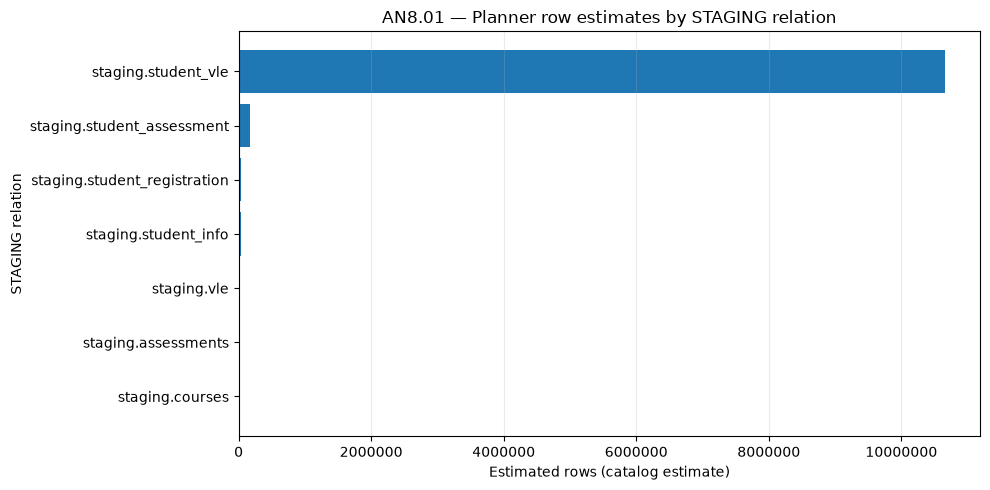

In [3]:
# 17.01. Create the CSV-backed visualization.
fig, ax = plt.subplots(figsize=(10, 5))
plot = csv_an801.sort_values("estimated_rows", ascending=True)
ax.barh(plot["source_relation"], plot["estimated_rows"])
ax.set_title("AN8.01 — Planner row estimates by STAGING relation")
ax.set_xlabel("Estimated rows (catalog estimate)")
ax.set_ylabel("STAGING relation")
ax.ticklabel_format(axis="x", style="plain")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** Read this as catalog metadata, not a replacement for exact row-count reconciliation. The relation-existence gate passed; the estimated row values are not authoritative population counts.

### AN8.02 — Student-presentation grain and key-set checks

This result set contains source-grain checks for student_info and student_registration plus the two directions of the key-set comparison. The validated key is (code_module, code_presentation, id_student).

**CSV source:** `AN8_02_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [4]:
# 17.02. Load and inspect this result set from its exported CSV file only.
csv_an802 = load_an8_csv("AN8_02_result_01.csv")

AN8_02_result_01.csv | 4 rows × 7 columns


,check_type,check_name,source_rows,distinct_keys,duplicate_key_groups,null_key_rows,key_count
0,KEY_DIFFERENCE,INFO_NOT_REGISTRATION,NaN,NaN,NaN,NaN,0.0
1,KEY_DIFFERENCE,REGISTRATION_NOT_INFO,NaN,NaN,NaN,NaN,0.0
2,SOURCE_GRAIN,student_info,32593.0,32593.0,0.0,0.0,NaN
3,SOURCE_GRAIN,student_registration,32593.0,32593.0,0.0,0.0,NaN


#### Visualization — AN8.02 — Student-presentation grain and key-set checks

Separate population/key counts from duplicate and NULL-key diagnostics so that the large denominator does not visually hide zero-valued integrity checks.

The chart below is derived only from `csv_an802`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

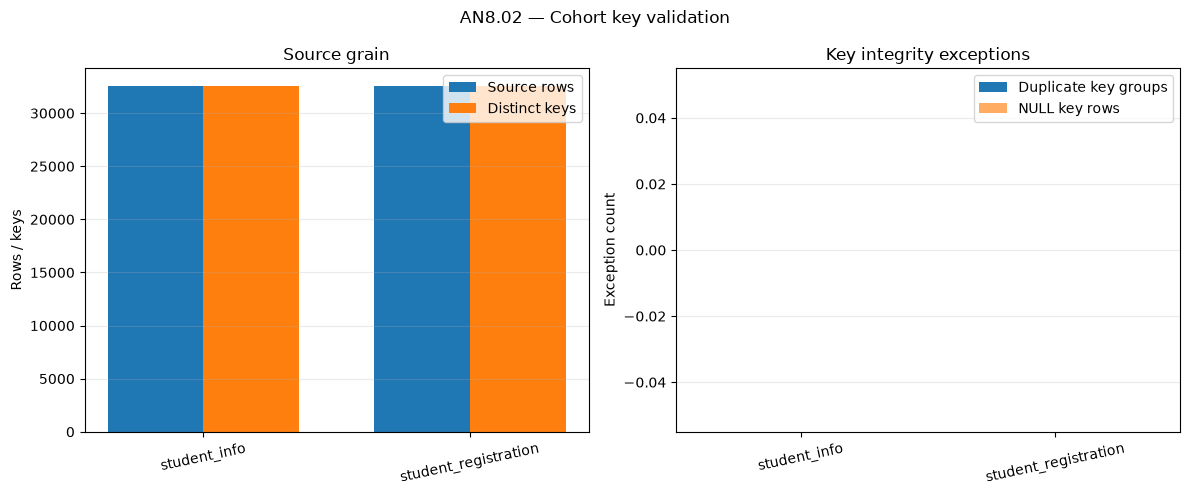

Bidirectional key-set differences: [{'check_name': 'INFO_NOT_REGISTRATION', 'key_count': 0.0}, {'check_name': 'REGISTRATION_NOT_INFO', 'key_count': 0.0}]


In [5]:
# 17.02. Create the CSV-backed visualization.
source = csv_an802.loc[csv_an802["check_type"].eq("SOURCE_GRAIN")].copy()
diffs = csv_an802.loc[csv_an802["check_type"].eq("KEY_DIFFERENCE")].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = range(len(source))
axes[0].bar([i - 0.18 for i in x], source["source_rows"], width=0.36, label="Source rows")
axes[0].bar([i + 0.18 for i in x], source["distinct_keys"], width=0.36, label="Distinct keys")
axes[0].set_xticks(list(x), source["check_name"], rotation=12)
axes[0].set_title("Source grain")
axes[0].set_ylabel("Rows / keys")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(source["check_name"], source["duplicate_key_groups"], label="Duplicate key groups")
axes[1].bar(source["check_name"], source["null_key_rows"], alpha=0.65, label="NULL key rows")
axes[1].set_title("Key integrity exceptions")
axes[1].set_ylabel("Exception count")
axes[1].tick_params(axis="x", rotation=12)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)
fig.suptitle("AN8.02 — Cohort key validation")
fig.tight_layout()
plt.show()
print("Bidirectional key-set differences:", diffs[["check_name", "key_count"]].to_dict("records"))

**Interpretation boundary:** Both sources contain 32,593 rows and 32,593 distinct keys, with no duplicate or NULL-key rows. Both directions of the key-set comparison returned zero differences. This validates this specific relationship, not every join in the analytical model.

### AN8.03 — Retrospective outcome denominator

This result set describes the four final_result categories at student-presentation grain and reconciles them to registration. Category-specific distinct student IDs are not additive across presentations.

**CSV source:** `AN8_03_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [6]:
# 17.03. Load and inspect this result set from its exported CSV file only.
csv_an803 = load_an8_csv("AN8_03_result_01.csv")

AN8_03_result_01.csv | 4 rows × 4 columns


,final_result,student_presentation_rows,registration_matched_rows,distinct_student_ids_in_category
0,Distinction,3024,3024,2903
1,Fail,7052,7052,6810
2,Pass,12361,12361,11881
3,Withdrawn,10156,10156,9155


#### Visualization — AN8.03 — Retrospective outcome denominator

Show both the count and percentage of the validated 32,593 student-presentation records, retaining Withdrawn as its own category.

The chart below is derived only from `csv_an803`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

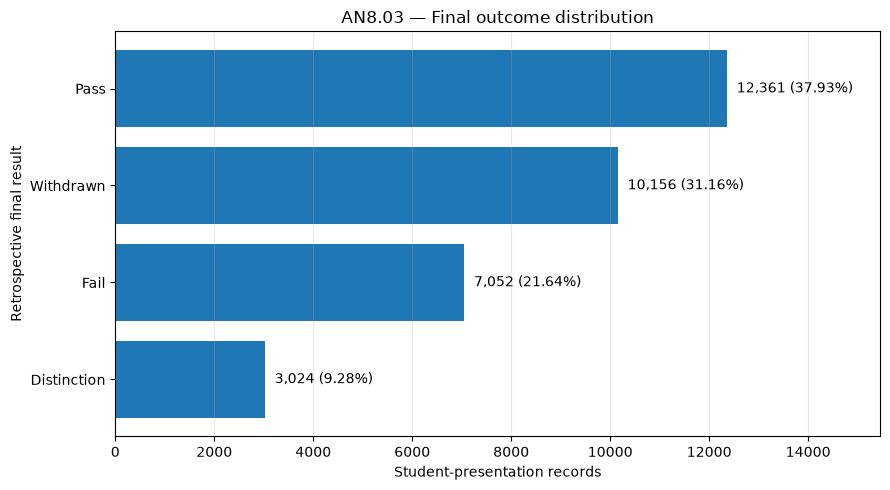

Denominator: 32593


In [7]:
# 17.03. Create the CSV-backed visualization.
plot = csv_an803.sort_values("student_presentation_rows")
denominator = int(plot["student_presentation_rows"].sum())
plot = plot.copy()
plot["share_pct"] = plot["student_presentation_rows"] / denominator * 100
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot["final_result"], plot["student_presentation_rows"])
for bar, count, share in zip(bars, plot["student_presentation_rows"], plot["share_pct"]):
    ax.text(bar.get_width() + denominator * 0.006, bar.get_y() + bar.get_height()/2,
            f"{int(count):,} ({share:.2f}%)", va="center")
ax.set_title("AN8.03 — Final outcome distribution")
ax.set_xlabel("Student-presentation records")
ax.set_ylabel("Retrospective final result")
ax.set_xlim(0, plot["student_presentation_rows"].max() * 1.25)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
print("Denominator:", denominator)

**Interpretation boundary:** Pass is the largest category, followed by Withdrawn, Fail, and Distinction. These are retrospective cohort labels, not early-warning signals or causal explanations.

### AN8.04.1 — Course presentation context

This is the first AN8.04 result set: one course-presentation context row per module and presentation, including the course length used in temporal activity definitions.

**CSV source:** `AN8_04_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [8]:
# 17.04. Load and inspect this result set from its exported CSV file only.
csv_an804_courses = load_an8_csv("AN8_04_result_01.csv")

AN8_04_result_01.csv | 22 rows × 3 columns


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013B,240
3,BBB,2013J,268
4,BBB,2014B,234
5,BBB,2014J,262
6,CCC,2014B,241
7,CCC,2014J,269
8,DDD,2013B,240
9,DDD,2013J,261


#### Visualization — AN8.04.1 — Course presentation context

Compare presentation lengths while retaining the module-presentation labels; the chart does not imply that longer presentations necessarily generate more activity.

The chart below is derived only from `csv_an804_courses`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

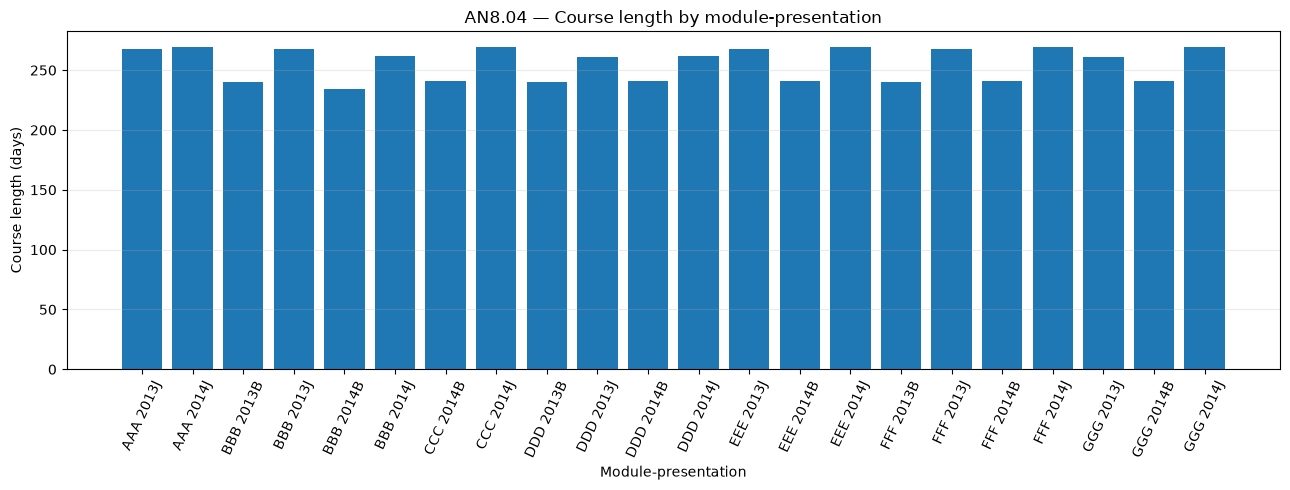

In [9]:
# 17.04. Create the CSV-backed visualization.
plot = csv_an804_courses.sort_values(["code_module", "code_presentation"]).copy()
labels = plot["code_module"] + " " + plot["code_presentation"]
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(labels, plot["module_presentation_length"])
ax.set_title("AN8.04 — Course length by module-presentation")
ax.set_xlabel("Module-presentation")
ax.set_ylabel("Course length (days)")
ax.tick_params(axis="x", rotation=65)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** Course length varies across presentations. The inclusive temporal boundaries used in activity metrics must be interpreted with the corresponding presentation-specific course length.

### AN8.04.2 — Assessment context

This is the second AN8.04 result set. It summarizes assessment count, missing due dates, and total assessment weight by module-presentation. Due dates and weights do not establish when scores or feedback became available.

**CSV source:** `AN8_04_result_02.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [10]:
# 17.05. Load and inspect this result set from its exported CSV file only.
csv_an804_assessments = load_an8_csv("AN8_04_result_02.csv")

AN8_04_result_02.csv | 22 rows × 5 columns


,code_module,code_presentation,assessment_count,missing_due_dates,total_weight
0,AAA,2013J,6,1,200.0
1,AAA,2014J,6,1,200.0
2,BBB,2013B,12,1,200.0
3,BBB,2013J,12,1,200.0
4,BBB,2014B,12,1,200.0
5,BBB,2014J,6,1,200.0
6,CCC,2014B,10,2,300.0
7,CCC,2014J,10,2,300.0
8,DDD,2013B,14,0,200.0
9,DDD,2013J,7,0,200.0


#### Visualization — AN8.04.2 — Assessment context

Use separate panels for assessment volume and missing due dates, and total weight. This avoids combining measures with different units on one axis.

The chart below is derived only from `csv_an804_assessments`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

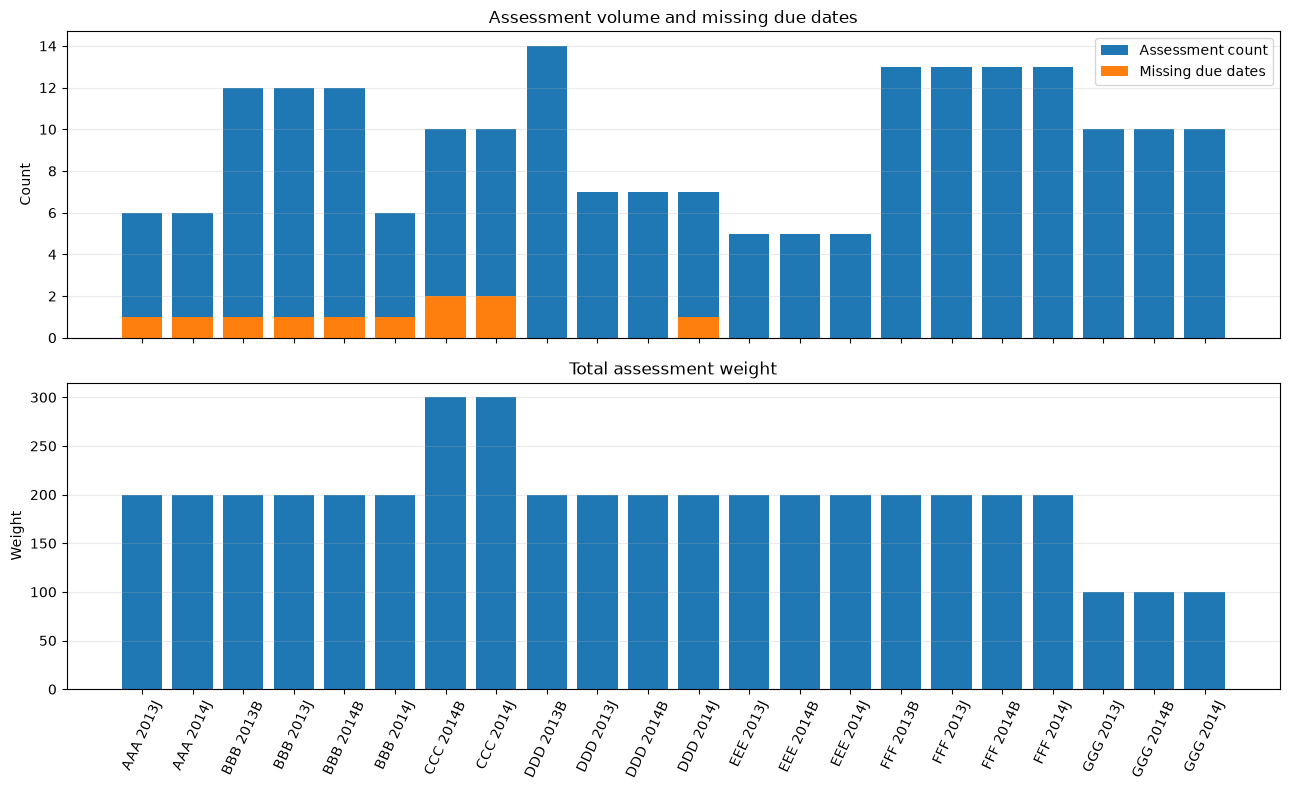

In [11]:
# 17.05. Create the CSV-backed visualization.
plot = csv_an804_assessments.sort_values(["code_module", "code_presentation"]).copy()
labels = plot["code_module"] + " " + plot["code_presentation"]
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].bar(labels, plot["assessment_count"], label="Assessment count")
axes[0].bar(labels, plot["missing_due_dates"], label="Missing due dates")
axes[0].set_ylabel("Count")
axes[0].set_title("Assessment volume and missing due dates")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(labels, plot["total_weight"])
axes[1].set_title("Total assessment weight")
axes[1].set_ylabel("Weight")
axes[1].grid(axis="y", alpha=0.25)
axes[1].tick_params(axis="x", rotation=65)
fig.tight_layout()
plt.show()

**Interpretation boundary:** The table is course-presentation context only. Missing due dates and total weight are useful metadata-quality and structure signals; they do not define assessment participation or score availability.

### AN8.10 — Registration timing

This result set classifies registration dates relative to the course start. The four states preserve missing registration dates rather than treating them as early or late registrations.

**CSV source:** `AN8_10_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [12]:
# 17.06. Load and inspect this result set from its exported CSV file only.
csv_an810 = load_an8_csv("AN8_10_result_01.csv")

AN8_10_result_01.csv | 4 rows × 2 columns


,registration_timing,registrations
0,AFTER_START,234
1,BEFORE_START,32312
2,MISSING,45
3,ON_START,2


#### Visualization — AN8.10 — Registration timing

Plot the counts by registration-timing state and annotate the total cohort denominator.

The chart below is derived only from `csv_an810`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

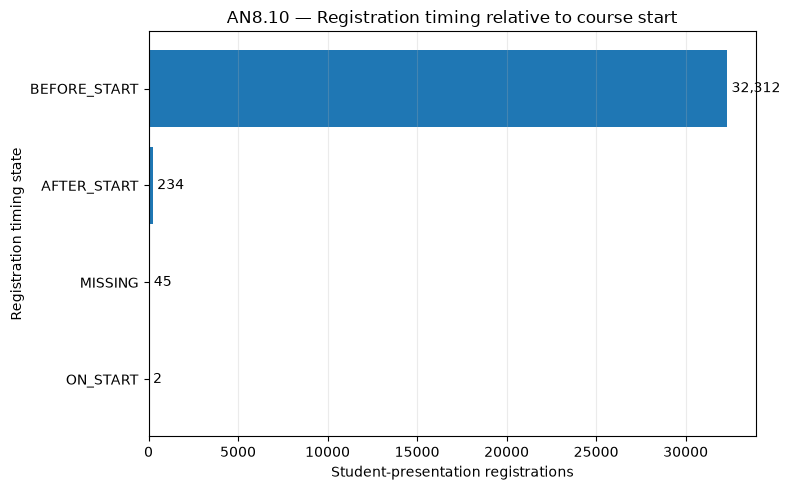

In [13]:
# 17.06. Create the CSV-backed visualization.
plot = csv_an810.sort_values("registrations")
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(plot["registration_timing"], plot["registrations"])
for bar, value in zip(bars, plot["registrations"]):
    ax.text(bar.get_width() + 250, bar.get_y() + bar.get_height()/2, f"{int(value):,}", va="center")
ax.set_title("AN8.10 — Registration timing relative to course start")
ax.set_xlabel("Student-presentation registrations")
ax.set_ylabel("Registration timing state")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** The observed distribution is dominated by BEFORE_START. The 45 MISSING dates remain an explicit data-quality state and should not be imputed without a documented rule.

### AN8.11 — Unregistration-date state by final result

This result set cross-tabulates retrospective final_result with the presence or absence of an unregistration date. It retains the small groups rather than silently combining categories.

**CSV source:** `AN8_11_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [14]:
# 17.07. Load and inspect this result set from its exported CSV file only.
csv_an811 = load_an8_csv("AN8_11_result_01.csv")

AN8_11_result_01.csv | 6 rows × 3 columns


,final_result,unregistration_state,student_presentations
0,Distinction,NO_UNREGISTRATION_DATE,3024
1,Fail,HAS_UNREGISTRATION_DATE,9
2,Fail,NO_UNREGISTRATION_DATE,7043
3,Pass,NO_UNREGISTRATION_DATE,12361
4,Withdrawn,HAS_UNREGISTRATION_DATE,10063
5,Withdrawn,NO_UNREGISTRATION_DATE,93


#### Visualization — AN8.11 — Unregistration-date state by final result

Use a stacked bar chart to show the state composition within each retrospective outcome category.

The chart below is derived only from `csv_an811`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

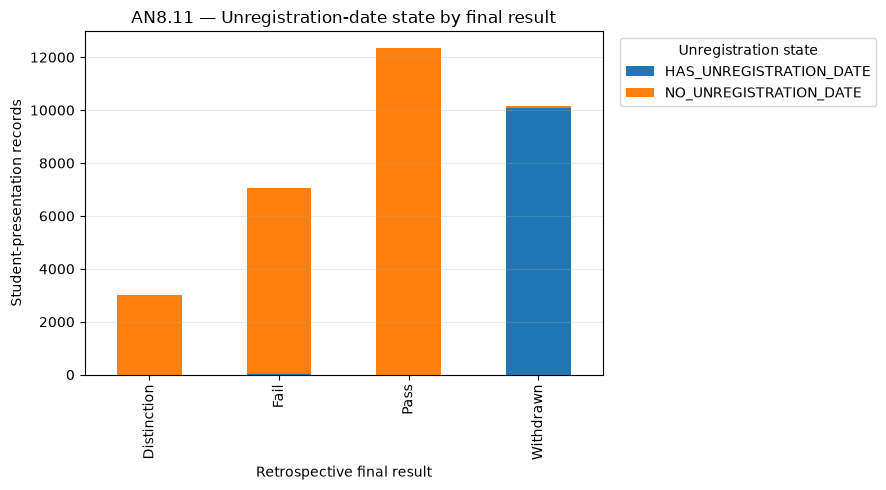

In [15]:
# 17.07. Create the CSV-backed visualization.
pivot = csv_an811.pivot_table(index="final_result", columns="unregistration_state",
                                  values="student_presentations", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5))
pivot.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("AN8.11 — Unregistration-date state by final result")
ax.set_xlabel("Retrospective final result")
ax.set_ylabel("Student-presentation records")
ax.legend(title="Unregistration state", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** Withdrawn records are overwhelmingly associated with a recorded unregistration date, but the table also contains Withdrawn records without one. Fail includes a small group with an unregistration date. These are source-state associations, not a causal explanation of the outcome.

### AN8.12 — Assessment score states

This result set classifies student-assessment records into NONZERO_SCORE, OBSERVED_ZERO, and NULL_SCORE. It is not a complete participation table: no-submission opportunities are analyzed separately in AN8.35.

**CSV source:** `AN8_12_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [16]:
# 17.08. Load and inspect this result set from its exported CSV file only.
csv_an812 = load_an8_csv("AN8_12_result_01.csv")

AN8_12_result_01.csv | 3 rows × 2 columns


,score_state,student_assessment_rows
0,NONZERO_SCORE,173410
1,NULL_SCORE,173
2,OBSERVED_ZERO,329


#### Visualization — AN8.12 — Assessment score states

Show the three score states on a count scale and preserve the small NULL and observed-zero categories.

The chart below is derived only from `csv_an812`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

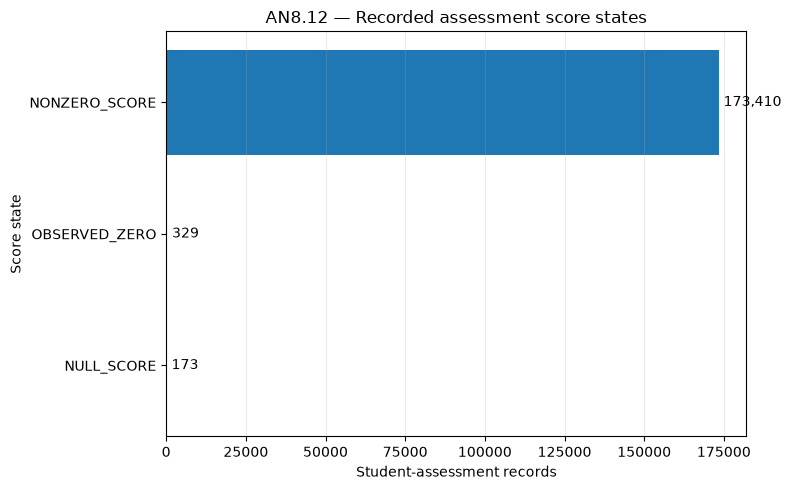

In [17]:
# 17.08. Create the CSV-backed visualization.
plot = csv_an812.sort_values("student_assessment_rows")
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(plot["score_state"], plot["student_assessment_rows"])
for bar, value in zip(bars, plot["student_assessment_rows"]):
    ax.text(bar.get_width() + 1500, bar.get_y() + bar.get_height()/2, f"{int(value):,}", va="center")
ax.set_title("AN8.12 — Recorded assessment score states")
ax.set_xlabel("Student-assessment records")
ax.set_ylabel("Score state")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** A NULL score and an observed score of zero are different recorded states. Neither should be collapsed into the other. No-submission opportunities are outside this particular result set.

### AN8.20 — Registered student-presentation activity extract

This is the consolidated student-presentation extract. It contains one row per registered student-presentation and includes course-relative activity, post-registration exposure, active days, resource breadth, and source reconciliation totals. The 32,593-row file is sampled in the display to keep the notebook readable; all rows remain available in the DataFrame.

**CSV source:** `AN8_20_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [18]:
# 17.09. Load and inspect this result set from its exported CSV file only.
csv_an820 = load_an8_csv("AN8_20_result_01.csv")

AN8_20_result_01.csv | 32,593 rows × 37 columns
Preview only (the complete DataFrame remains available for analysis):


,code_module,code_presentation,id_student,date_registration,course_length,exposure_start,post_registration_exposure_days,all_observed_activity_rows,all_observed_recorded_clicks,pre_course_activity_rows,...,matched_registered_recorded_clicks,unmatched_recorded_clicks,all_source_in_course_activity_rows,all_source_pre_course_activity_rows,all_source_post_course_activity_rows,all_source_no_course_window_activity_rows,all_source_pre_course_recorded_clicks,all_source_in_course_recorded_clicks,all_source_post_course_recorded_clicks,all_source_no_course_window_recorded_clicks
0,AAA,2013J,11391,-159.0,268,0.0,269.0,196,934,11,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
1,AAA,2013J,28400,-53.0,268,0.0,269.0,430,1435,55,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
2,AAA,2013J,30268,-92.0,268,0.0,269.0,76,281,34,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
3,AAA,2013J,31604,-52.0,268,0.0,269.0,663,2158,38,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
4,AAA,2013J,32885,-176.0,268,0.0,269.0,352,1034,66,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0


,code_module,code_presentation,id_student,date_registration,course_length,exposure_start,post_registration_exposure_days,all_observed_activity_rows,all_observed_recorded_clicks,pre_course_activity_rows,...,matched_registered_recorded_clicks,unmatched_recorded_clicks,all_source_in_course_activity_rows,all_source_pre_course_activity_rows,all_source_post_course_activity_rows,all_source_no_course_window_activity_rows,all_source_pre_course_recorded_clicks,all_source_in_course_recorded_clicks,all_source_post_course_recorded_clicks,all_source_no_course_window_recorded_clicks
32588,GGG,2014J,2640965,-4.0,269,0.0,270.0,19,41,1,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
32589,GGG,2014J,2645731,-23.0,269,0.0,270.0,237,893,0,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
32590,GGG,2014J,2648187,-129.0,269,0.0,270.0,108,312,7,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
32591,GGG,2014J,2679821,-49.0,269,0.0,270.0,61,275,19,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0
32592,GGG,2014J,2684003,-28.0,269,0.0,270.0,181,616,43,...,39605099,0,9966292,688988,0,0,2147947,37457152,0,0


#### Visualization — AN8.20 — Registered student-presentation activity extract

Use distributions and an exposure-versus-active-days density plot. The post-registration measures remain NULL where registration timing is unknown or no course exposure is available.

The chart below is derived only from `csv_an820`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

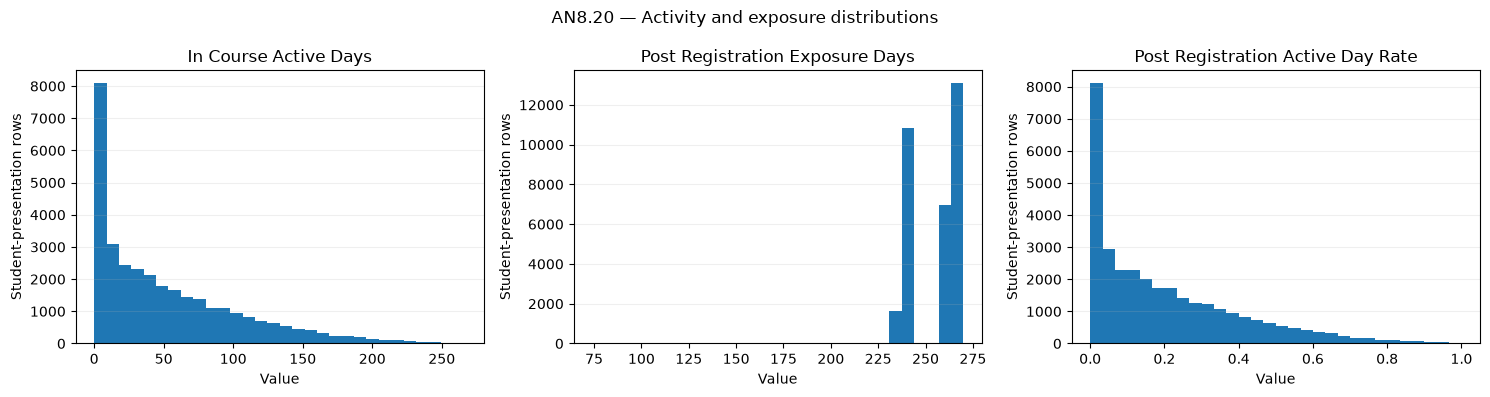

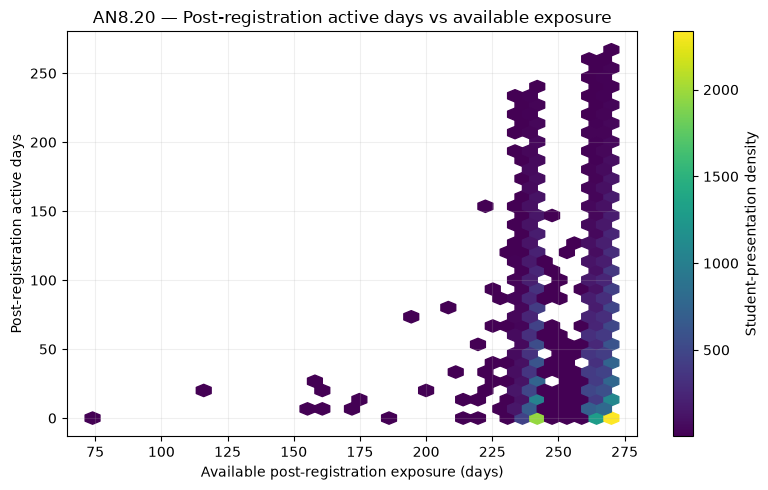

Rows with unknown exposure: 45
Rows with no recorded activity: 3365


In [19]:
# 17.09. Create the CSV-backed visualization.
numeric_columns = ["in_course_active_days", "post_registration_exposure_days",
                    "post_registration_active_day_rate"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, numeric_columns):
    values = pd.to_numeric(csv_an820[column], errors="coerce").dropna()
    ax.hist(values, bins=30)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("Student-presentation rows")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("AN8.20 — Activity and exposure distributions")
fig.tight_layout()
plt.show()

scatter = csv_an820[["post_registration_exposure_days", "post_registration_active_days"]].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(scatter["post_registration_exposure_days"], scatter["post_registration_active_days"],
               gridsize=35, mincnt=1)
fig.colorbar(hb, ax=ax, label="Student-presentation density")
ax.set_title("AN8.20 — Post-registration active days vs available exposure")
ax.set_xlabel("Available post-registration exposure (days)")
ax.set_ylabel("Post-registration active days")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
print("Rows with unknown exposure:", int(csv_an820["post_registration_exposure_days"].isna().sum()))
print("Rows with no recorded activity:", int((~csv_an820["has_recorded_activity"]).sum()))

**Interpretation boundary:** The distributions describe recorded VLE activity and opportunity-to-observe, not learning quality. Missing registration dates must remain visible. Active days should be interpreted relative to available exposure; this motivates explicit metric contracts and sensitivity checks in Part 3.

### AN8.30.1 — R0/R1/R2 scenario comparison

This result set compares activity-row and recorded-click totals under R0, R1, and R2. R0 retains all recorded rows; R1 excludes exact six-column repeats for sensitivity; R2 retains MAX(sum_click) per five-column key for sensitivity.

**CSV source:** `AN8_30_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [20]:
# 17.10. Load and inspect this result set from its exported CSV file only.
csv_an830_scenarios = load_an8_csv("AN8_30_result_01.csv")

AN8_30_result_01.csv | 3 rows × 13 columns


,scenario,activity_rows,recorded_clicks,r0_rows,repeated_five_key_groups,excess_rows_over_five_key,multi_click_value_groups,maximum_five_key_group_size,nonpositive_click_rows,null_click_rows,min_clicks,max_clicks,pre_course_rows
0,R0,10655280,39605099,10655280,1614505,2195960,1179074,10,0,0,1,6977,688988
1,R1,9868110,38343063,10655280,1614505,2195960,1179074,10,0,0,1,6977,688988
2,R2,8459320,34402738,10655280,1614505,2195960,1179074,10,0,0,1,6977,688988


#### Visualization — AN8.30.1 — R0/R1/R2 scenario comparison

Index each scenario to R0 and compare percentage changes in activity rows and recorded clicks. This makes the difference in sensitivity visible without presenting R1 or R2 as corrected source truth.

The chart below is derived only from `csv_an830_scenarios`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

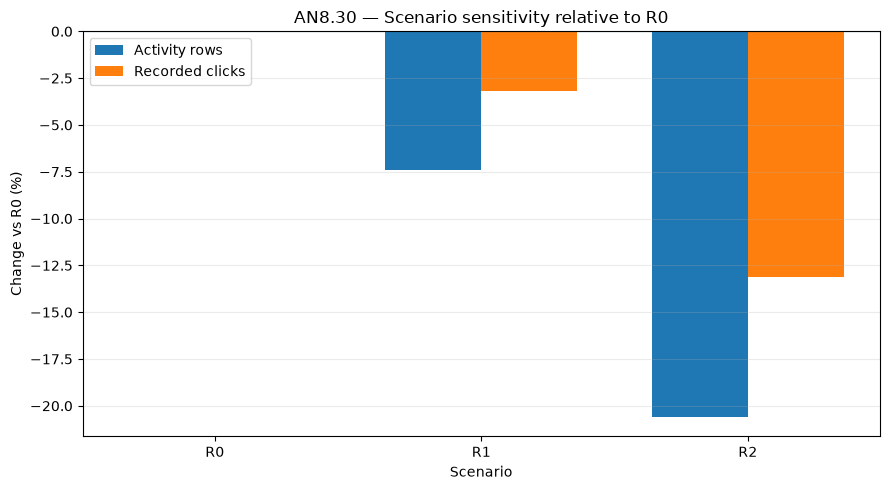

In [21]:
# 17.10. Create the CSV-backed visualization.
plot = csv_an830_scenarios.set_index("scenario").loc[["R0", "R1", "R2"]].copy()
base_rows = float(plot.loc["R0", "activity_rows"])
base_clicks = float(plot.loc["R0", "recorded_clicks"])
plot["activity_rows_delta_pct"] = (plot["activity_rows"] / base_rows - 1) * 100
plot["recorded_clicks_delta_pct"] = (plot["recorded_clicks"] / base_clicks - 1) * 100
fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(plot))
ax.bar([i - 0.18 for i in x], plot["activity_rows_delta_pct"], width=0.36, label="Activity rows")
ax.bar([i + 0.18 for i in x], plot["recorded_clicks_delta_pct"], width=0.36, label="Recorded clicks")
ax.set_xticks(list(x), plot.index)
ax.set_title("AN8.30 — Scenario sensitivity relative to R0")
ax.set_xlabel("Scenario")
ax.set_ylabel("Change vs R0 (%)")
ax.axhline(0, linewidth=0.8)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** R1 and R2 reduce row and click totals by different amounts. The scenarios quantify sensitivity to repeated-row handling; neither establishes the true intended value of repeated records and neither is an approved cleaning rule.

### AN8.30.2 — Activity source/reference states

This result set decomposes source activity by registration, course, resource, and temporal matching states. It is a diagnostic of reference coverage and temporal classification, not a cleaning decision.

**CSV source:** `AN8_30_result_02.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [22]:
# 17.11. Load and inspect this result set from its exported CSV file only.
csv_an830_states = load_an8_csv("AN8_30_result_02.csv")

AN8_30_result_02.csv | 2 rows × 6 columns


,registration_state,course_state,resource_state,temporal_state,source_rows,recorded_clicks
0,REGISTRATION_MATCH,COURSE_MATCH,VLE_RESOURCE_MATCH,IN_COURSE,9966292,37457152
1,REGISTRATION_MATCH,COURSE_MATCH,VLE_RESOURCE_MATCH,PRE_COURSE,688988,2147947


#### Visualization — AN8.30.2 — Activity source/reference states

Summarize recorded source rows by temporal_state. Retain the detailed state columns in the DataFrame for later cross-tabulation during Part 3.

The chart below is derived only from `csv_an830_states`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

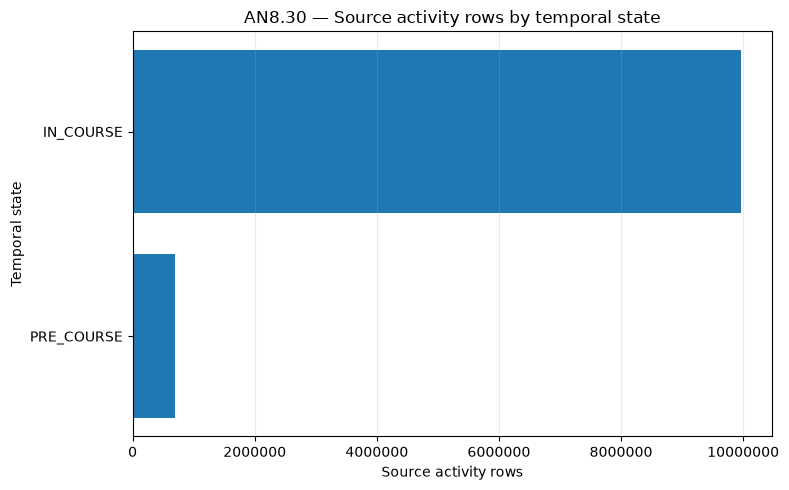

In [23]:
# 17.11. Create the CSV-backed visualization.
plot = csv_an830_states.groupby("temporal_state", as_index=False)["source_rows"].sum().sort_values("source_rows")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot["temporal_state"], plot["source_rows"])
ax.set_title("AN8.30 — Source activity rows by temporal state")
ax.set_xlabel("Source activity rows")
ax.set_ylabel("Temporal state")
ax.ticklabel_format(axis="x", style="plain")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** Temporal categories should be interpreted with the presentation-relative time definition. A PRE_COURSE row is before the presentation start, not necessarily before an individual student's registration.

### AN8.31 — Zero-inclusive activity distributions

This result set contains presentation-level distributions for four activity measures and retains registered student-presentations with zero activity. The denominator is the registered population for each module-presentation.

**CSV source:** `AN8_31_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [24]:
# 17.12. Load and inspect this result set from its exported CSV file only.
csv_an831 = load_an8_csv("AN8_31_result_01.csv")

AN8_31_result_01.csv | 88 rows × 12 columns
Preview only (the complete DataFrame remains available for analysis):


,code_module,code_presentation,metric,registered_denominator,zero_value_count,pct_zero,mean_value,p25,median,p75,p90,max_value
0,AAA,2013J,ACTIVE_DAYS,383,7,1.83,84.74,38.5,76.0,119.5,169.0,261
1,AAA,2013J,ACTIVITY_ROWS,383,7,1.83,444.22,178.0,333.0,585.0,916.4,2140
2,AAA,2013J,RECORDED_CLICKS,383,7,1.83,1563.63,519.5,1102.0,1911.5,3480.2,12213
3,AAA,2013J,RESOURCE_BREADTH,383,7,1.83,58.85,42.5,60.0,78.0,87.0,121
4,AAA,2014J,ACTIVE_DAYS,365,13,3.56,77.21,31.0,64.0,117.0,154.6,262


,code_module,code_presentation,metric,registered_denominator,zero_value_count,pct_zero,mean_value,p25,median,p75,p90,max_value
83,GGG,2014B,RESOURCE_BREADTH,833,67,8.04,27.68,14.0,29.0,41.0,49.0,72
84,GGG,2014J,ACTIVE_DAYS,749,60,8.01,32.26,8.0,27.0,46.0,68.0,240
85,GGG,2014J,ACTIVITY_ROWS,749,60,8.01,146.51,44.0,125.0,213.0,283.0,1479
86,GGG,2014J,RECORDED_CLICKS,749,60,8.01,500.92,109.0,407.0,719.0,1053.6,7408
87,GGG,2014J,RESOURCE_BREADTH,749,60,8.01,29.11,14.0,31.0,42.0,51.0,71


#### Visualization — AN8.31 — Zero-inclusive activity distributions

Compare the distribution of pct_zero across presentations for ACTIVE_DAYS, ACTIVITY_ROWS, RECORDED_CLICKS, and RESOURCE_BREADTH. A boxplot shows between-presentation variation without pooling raw student records.

The chart below is derived only from `csv_an831`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

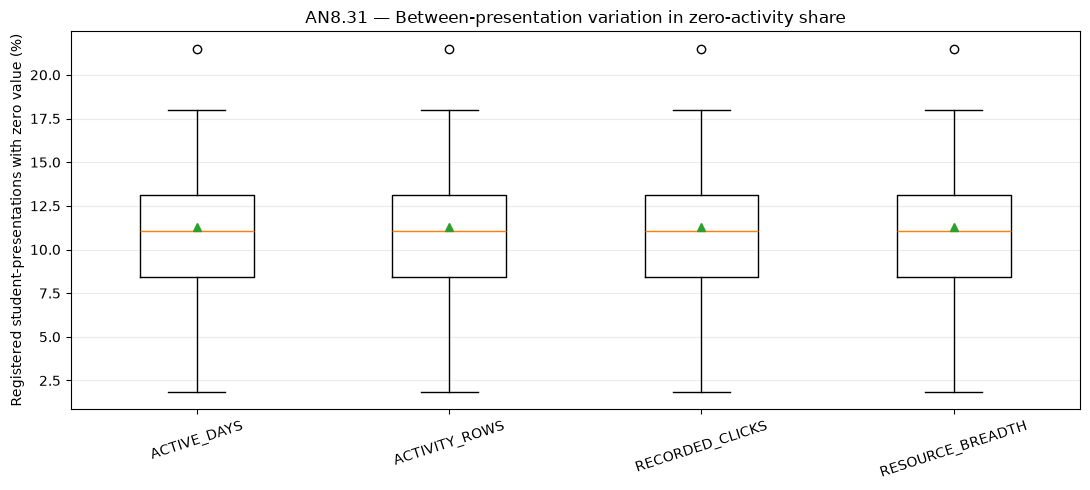

In [25]:
# 17.12. Create the CSV-backed visualization.
metrics = list(csv_an831["metric"].dropna().unique())
data = [csv_an831.loc[csv_an831["metric"].eq(metric), "pct_zero"].dropna() for metric in metrics]
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(data, tick_labels=metrics, showmeans=True)
ax.set_title("AN8.31 — Between-presentation variation in zero-activity share")
ax.set_ylabel("Registered student-presentations with zero value (%)")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** The zero share and the median are different dimensions of the distribution. Row and click measures remain sensitive to repeated student_vle records, while active days and resource breadth are distinct-value measures. Zero activity in the extract means no matching recorded activity under the defined window, not absence of learning.

### AN8.32 — Registration timing and exposure days

This result set summarizes available exposure by module-presentation and registration state. It distinguishes unknown exposure, zero exposure, and positive exposure; exposure is an opportunity-to-observe measure, not attendance.

**CSV source:** `AN8_32_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [26]:
# 17.13. Load and inspect this result set from its exported CSV file only.
csv_an832 = load_an8_csv("AN8_32_result_01.csv")

AN8_32_result_01.csv | 61 rows × 11 columns
Preview only (the complete DataFrame remains available for analysis):


,code_module,code_presentation,registration_state,registered_student_presentations,unknown_exposure_count,zero_exposure_count,positive_exposure_count,min_exposure_days,median_exposure_days,p90_exposure_days,max_exposure_days
0,AAA,2013J,AFTER_COURSE_START,4,0,0,4,221.0,256.5,266.1,267.0
1,AAA,2013J,BEFORE_COURSE_START,379,0,0,379,269.0,269.0,269.0,269.0
2,AAA,2014J,AFTER_COURSE_START,4,0,0,4,260.0,266.0,267.7,268.0
3,AAA,2014J,BEFORE_COURSE_START,361,0,0,361,270.0,270.0,270.0,270.0
4,BBB,2013B,AFTER_COURSE_START,9,0,0,9,172.0,232.0,238.2,239.0


,code_module,code_presentation,registration_state,registered_student_presentations,unknown_exposure_count,zero_exposure_count,positive_exposure_count,min_exposure_days,median_exposure_days,p90_exposure_days,max_exposure_days
56,GGG,2014B,AFTER_COURSE_START,2,0,0,2,236.0,238.0,239.6,240.0
57,GGG,2014B,BEFORE_COURSE_START,831,0,0,831,242.0,242.0,242.0,242.0
58,GGG,2014J,AFTER_COURSE_START,43,0,0,43,251.0,267.0,268.0,268.0
59,GGG,2014J,BEFORE_COURSE_START,705,0,0,705,270.0,270.0,270.0,270.0
60,GGG,2014J,ON_COURSE_START,1,0,0,1,270.0,270.0,270.0,270.0


#### Visualization — AN8.32 — Registration timing and exposure days

Aggregate the registered student-presentation counts into unknown, zero, and positive exposure states by registration timing. This preserves the different states instead of replacing unknown exposure with zero.

The chart below is derived only from `csv_an832`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

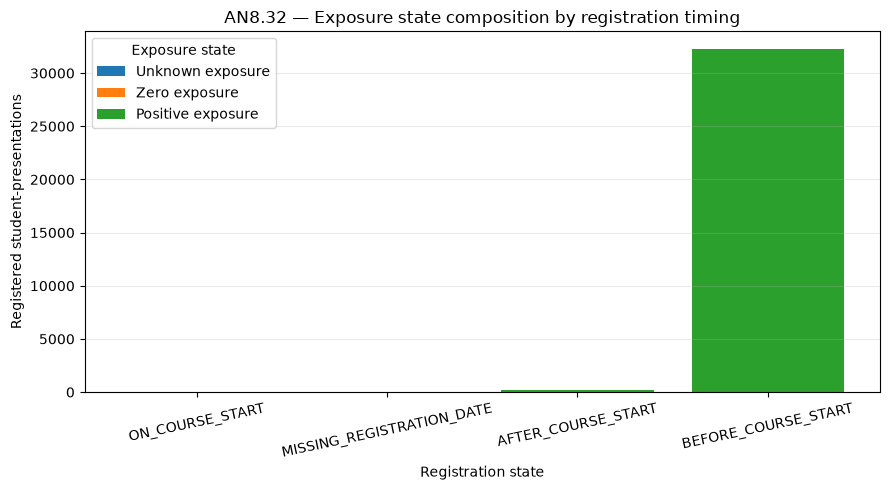

In [27]:
# 17.13. Create the CSV-backed visualization.
grouped = csv_an832.groupby("registration_state", as_index=False)[
    ["registered_student_presentations", "unknown_exposure_count",
     "zero_exposure_count", "positive_exposure_count"]
].sum()
grouped = grouped.sort_values("registered_student_presentations")
fig, ax = plt.subplots(figsize=(9, 5))
bottom = pd.Series(0, index=grouped.index, dtype="int64")
for column, label in [("unknown_exposure_count", "Unknown exposure"),
                      ("zero_exposure_count", "Zero exposure"),
                      ("positive_exposure_count", "Positive exposure")]:
    ax.bar(grouped["registration_state"], grouped[column], bottom=bottom, label=label)
    bottom = bottom + grouped[column]
ax.set_title("AN8.32 — Exposure state composition by registration timing")
ax.set_xlabel("Registration state")
ax.set_ylabel("Registered student-presentations")
ax.legend(title="Exposure state")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** Unknown exposure and zero exposure are not interchangeable. Registration after course end can produce zero available exposure, while missing registration timing remains unknown. The denominator is registered student-presentations in each state.

### AN8.33 — Candidate metric register

This result set records operational definitions, grain, denominator, limitations, and approval status for eight candidate metrics. The register is a design and governance artifact, not a KPI approval.

**CSV source:** `AN8_33_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [28]:
# 17.14. Load and inspect this result set from its exported CSV file only.
csv_an833 = load_an8_csv("AN8_33_result_01.csv")

AN8_33_result_01.csv | 8 rows × 6 columns


,metric_id,operational_definition,grain,denominator,limitation,approval_status
0,assessment_score,score,student-assessment,Observed non-NULL scores,Retrospective; availability time not established,CANDIDATE_NOT_APPROVED
1,final_result,final_result,student-presentation,Validated student_info cohort,Outcome only; never an early predictor,OUTCOME_ONLY
2,in_course_active_days,COUNT(DISTINCT date),student-presentation,All registered keys including zero,Day-level; same-day event order unavailable,CANDIDATE_NOT_APPROVED
3,in_course_activity_presence,has at least one source row in inclusive cours...,student-presentation,All registered keys,No recorded row is not proof of no learning,CANDIDATE_NOT_APPROVED
4,in_course_resource_breadth,COUNT(DISTINCT id_site),student-presentation,All registered keys including zero,Resource breadth is not learning quality,CANDIDATE_NOT_APPROVED
5,post_registration_active_day_rate,active days / available exposure days,student-presentation,Known positive exposure only,Unknown/zero exposure must remain separate,CANDIDATE_NOT_APPROVED
6,recorded_click_volume,SUM(sum_click),student-presentation,All registered keys,Sensitive to repeated source rows; secondary d...,CANDIDATE_NOT_APPROVED
7,registered_student_presentations,COUNT(*),student-presentation,All validated registration keys,Cohort size; not unique people,CANDIDATE_NOT_APPROVED


#### Visualization — AN8.33 — Candidate metric register

Summarize how many candidate metrics currently appear in each approval_status category. Keep the full register visible in the table cell for exact definitions and limitations.

The chart below is derived only from `csv_an833`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

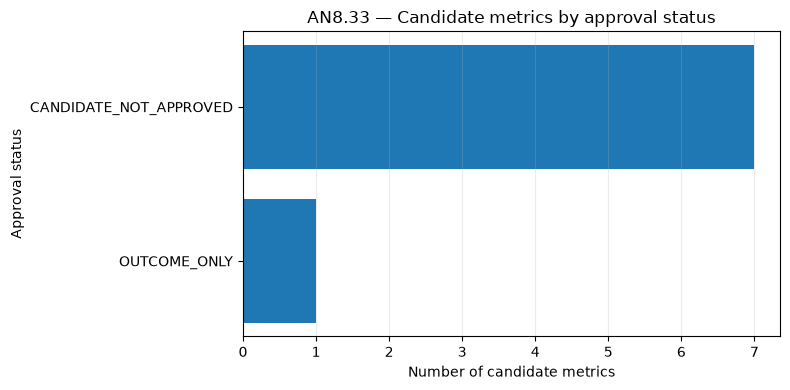

In [29]:
# 17.14. Create the CSV-backed visualization.
status_counts = csv_an833["approval_status"].fillna("MISSING_STATUS").value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(status_counts.index, status_counts.values)
ax.set_title("AN8.33 — Candidate metrics by approval status")
ax.set_xlabel("Number of candidate metrics")
ax.set_ylabel("Approval status")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** A candidate definition is not automatically an approved KPI. In particular, final_result is retrospective and cannot be treated as an early predictor of itself. The metric contract must specify time availability, grain, denominator, missingness, and intended use.

### AN8.34 — Activity by retrospective outcome and presentation

This result set reports presentation-specific activity summaries by final_result. Each row is a summary for a module-presentation, outcome, and metric; it must not be treated as an individual-level record.

**CSV source:** `AN8_34_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [30]:
# 17.15. Load and inspect this result set from its exported CSV file only.
csv_an834 = load_an8_csv("AN8_34_result_01.csv")

AN8_34_result_01.csv | 352 rows × 11 columns
Preview only (the complete DataFrame remains available for analysis):


,code_module,code_presentation,final_result,metric,student_presentation_denominator,zero_count,pct_zero,mean_value,median,p75,p90
0,AAA,2013J,Distinction,ACTIVE_DAYS,20,0,0.0,166.10,172.5,218.00,223.7
1,AAA,2013J,Distinction,ACTIVITY_ROWS,20,0,0.0,1009.70,828.5,1594.00,1758.6
2,AAA,2013J,Distinction,RECORDED_CLICKS,20,0,0.0,3781.10,2702.0,5247.00,6951.5
3,AAA,2013J,Distinction,RESOURCE_BREADTH,20,0,0.0,81.85,85.5,96.25,100.0
4,AAA,2013J,Fail,ACTIVE_DAYS,45,0,0.0,40.64,29.0,52.00,96.2


,code_module,code_presentation,final_result,metric,student_presentation_denominator,zero_count,pct_zero,mean_value,median,p75,p90
347,GGG,2014J,Pass,RESOURCE_BREADTH,317,0,0.00,39.21,39.0,46.00,54.4
348,GGG,2014J,Withdrawn,ACTIVE_DAYS,126,39,30.95,6.37,3.0,9.50,16.0
349,GGG,2014J,Withdrawn,ACTIVITY_ROWS,126,39,30.95,25.11,12.5,41.75,60.0
350,GGG,2014J,Withdrawn,RECORDED_CLICKS,126,39,30.95,67.46,37.0,96.50,191.5
351,GGG,2014J,Withdrawn,RESOURCE_BREADTH,126,39,30.95,8.47,8.0,14.00,19.0


#### Visualization — AN8.34 — Activity by retrospective outcome and presentation

Show the distribution of presentation-level medians by retrospective outcome, in separate panels for each activity metric. Each box summarizes the set of presentation-level medians, not a pooled student-level distribution.

The chart below is derived only from `csv_an834`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

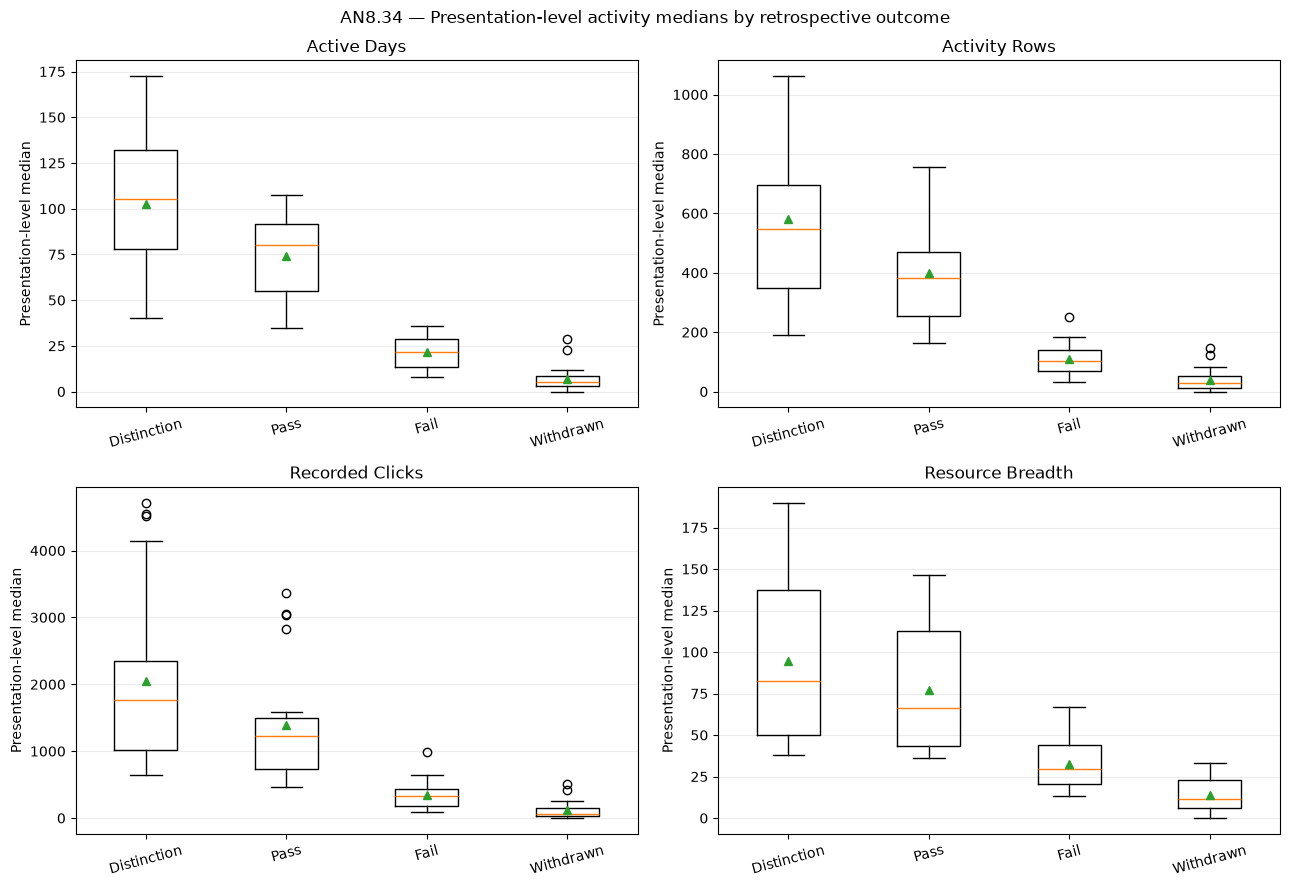

In [31]:
# 17.15. Create the CSV-backed visualization.
metric_order = list(csv_an834["metric"].dropna().unique())
outcome_order = ["Distinction", "Pass", "Fail", "Withdrawn"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, metric_order):
    subset = csv_an834.loc[csv_an834["metric"].eq(metric)]
    values = [subset.loc[subset["final_result"].eq(outcome), "median"].dropna()
              for outcome in outcome_order]
    ax.boxplot(values, tick_labels=outcome_order, showmeans=True)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_ylabel("Presentation-level median")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("AN8.34 — Presentation-level activity medians by retrospective outcome")
fig.tight_layout()
plt.show()

**Interpretation boundary:** Outcome-group differences are descriptive and may reflect different cohort sizes, exposure, withdrawal timing, and activity-recording patterns. They do not establish that activity caused an outcome. Small presentation/outcome groups need explicit review before publication.

### AN8.35 — Assessment participation and score-state coverage

This result set separates NO_SUBMISSION, NULL_SCORE_ONLY, OBSERVED_ZERO_ONLY, NONZERO_SCORE_ONLY, and mixed score states at the assessment-type/presentation grain. Assessment opportunities repeat across assessment types and presentations.

**CSV source:** `AN8_35_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [32]:
# 17.16. Load and inspect this result set from its exported CSV file only.
csv_an835 = load_an8_csv("AN8_35_result_01.csv")

AN8_35_result_01.csv | 156 rows × 12 columns
Preview only (the complete DataFrame remains available for analysis):


,code_module,code_presentation,assessment_type,score_state,registered_assessment_opportunities,distinct_students,submission_rows,null_score_rows,opportunities_with_observed_zero,opportunities_with_nonzero_score,mean_of_student_scores,median_student_score
0,AAA,2013J,Exam,NO_SUBMISSION,383,383,0,0,0,0,NaN,NaN
1,AAA,2013J,TMA,NO_SUBMISSION,282,92,0,0,0,0,NaN,NaN
2,AAA,2013J,TMA,NONZERO_SCORE_ONLY,1630,364,1630,0,0,1630,69.47,72.0
3,AAA,2013J,TMA,NULL_SCORE_ONLY,2,2,2,2,0,0,NaN,NaN
4,AAA,2013J,TMA,OBSERVED_ZERO_ONLY,1,1,1,0,1,0,0.00,0.0


,code_module,code_presentation,assessment_type,score_state,registered_assessment_opportunities,distinct_students,submission_rows,null_score_rows,opportunities_with_observed_zero,opportunities_with_nonzero_score,mean_of_student_scores,median_student_score
151,GGG,2014J,Exam,NO_SUBMISSION,749,749,0,0,0,0,NaN,NaN
152,GGG,2014J,TMA,NO_SUBMISSION,621,263,0,0,0,0,NaN,NaN
153,GGG,2014J,TMA,NONZERO_SCORE_ONLY,1621,600,1621,0,0,1621,67.73,70.0
154,GGG,2014J,TMA,NULL_SCORE_ONLY,2,2,2,2,0,0,NaN,NaN
155,GGG,2014J,TMA,OBSERVED_ZERO_ONLY,3,3,3,0,3,0,0.00,0.0


#### Visualization — AN8.35 — Assessment participation and score-state coverage

Compare submission-row totals by score state. This is a count of recorded submission rows by state, not a unique-student total; the full table preserves the opportunity denominators and score summaries.

The chart below is derived only from `csv_an835`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

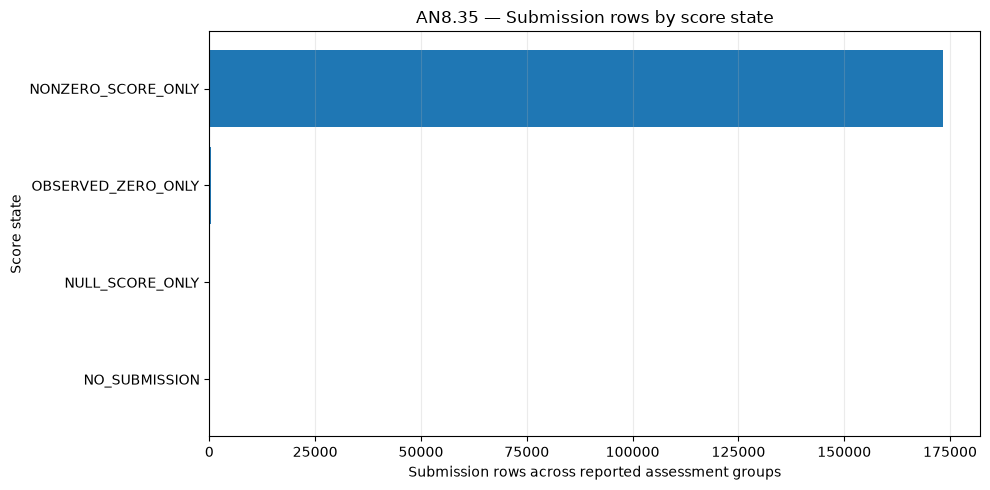

In [33]:
# 17.16. Create the CSV-backed visualization.
state_totals = csv_an835.groupby("score_state", as_index=False)[
    ["submission_rows", "null_score_rows", "opportunities_with_observed_zero",
     "opportunities_with_nonzero_score"]
].sum().sort_values("submission_rows")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(state_totals["score_state"], state_totals["submission_rows"])
ax.set_title("AN8.35 — Submission rows by score state")
ax.set_xlabel("Submission rows across reported assessment groups")
ax.set_ylabel("Score state")
ax.ticklabel_format(axis="x", style="plain")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation boundary:** No submission, a submitted record with NULL score, observed zero, nonzero score, and mixed score states are distinct. Do not add assessment opportunities across rows as if they were unique students. Assessment-level denominator contracts remain necessary.

### AN8.36 — Student-profile outcome segments

This result set contains 4,249 rows grouped by module-presentation, profile dimension, segment value, and retrospective final_result. Missing profile categories are retained where defined by the SQL. Segment counts and percentages are not a fairness assessment.

**CSV source:** `AN8_36_result_01.csv`  
**Review rule:** validate the file against the export manifest before interpreting it.

In [34]:
# 17.17. Load and inspect this result set from its exported CSV file only.
csv_an836 = load_an8_csv("AN8_36_result_01.csv")

AN8_36_result_01.csv | 4,249 rows × 7 columns
Preview only (the complete DataFrame remains available for analysis):


,code_module,code_presentation,dimension,segment_value,final_result,student_presentation_rows,pct_within_segment
0,AAA,2013J,AGE_BAND,0-35,Distinction,6,3.35
1,AAA,2013J,AGE_BAND,0-35,Fail,27,15.08
2,AAA,2013J,AGE_BAND,0-35,Pass,120,67.04
3,AAA,2013J,AGE_BAND,0-35,Withdrawn,26,14.53
4,AAA,2013J,AGE_BAND,35-55,Distinction,9,5.06


,code_module,code_presentation,dimension,segment_value,final_result,student_presentation_rows,pct_within_segment
4244,GGG,2014J,STUDIED_CREDITS,60,Withdrawn,17,68.00
4245,GGG,2014J,STUDIED_CREDITS,90,Distinction,4,19.05
4246,GGG,2014J,STUDIED_CREDITS,90,Fail,7,33.33
4247,GGG,2014J,STUDIED_CREDITS,90,Pass,5,23.81
4248,GGG,2014J,STUDIED_CREDITS,90,Withdrawn,5,23.81


#### Visualization — AN8.36 — Student-profile outcome segments

Build a heatmap from the median of presentation-segment percentages for each profile dimension and outcome. This is an exploratory comparison of summarized percentages, not a pooled or adjusted estimate.

The chart below is derived only from `csv_an836`, the DataFrame loaded from the CSV above. It does not query PostgreSQL.

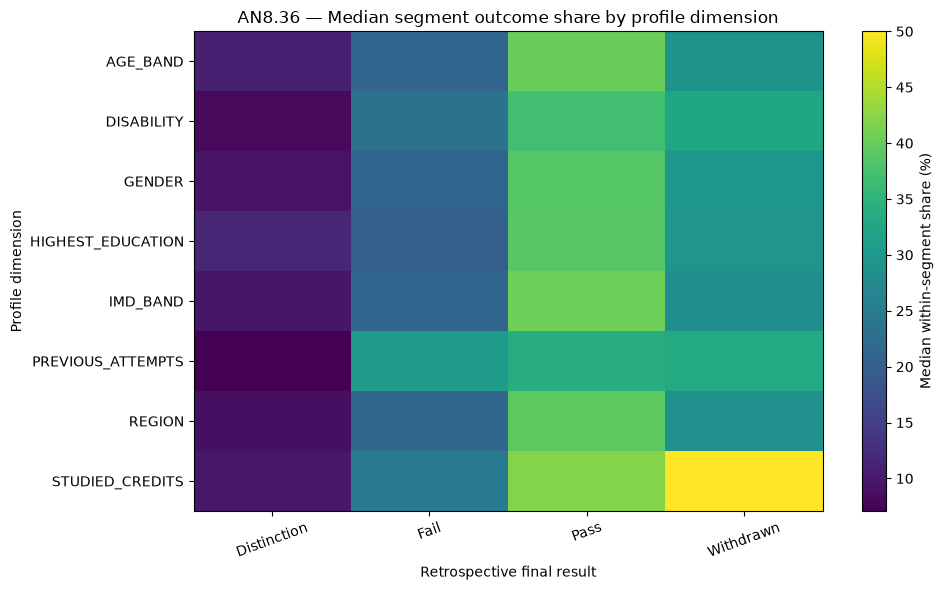

In [35]:
# 17.17. Create the CSV-backed visualization.
heat = csv_an836.pivot_table(index="dimension", columns="final_result",
                                values="pct_within_segment", aggfunc="median")
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(heat, aspect="auto")
ax.set_xticks(range(len(heat.columns)), heat.columns, rotation=20)
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_title("AN8.36 — Median segment outcome share by profile dimension")
ax.set_xlabel("Retrospective final result")
ax.set_ylabel("Profile dimension")
fig.colorbar(im, ax=ax, label="Median within-segment share (%)")
fig.tight_layout()
plt.show()

**Interpretation boundary:** The heatmap is a navigation aid for deeper analysis only. It does not establish a demographic effect, explain an outcome, or assess fairness. Part 3 should inspect missing categories, segment denominators, small cells, and presentation heterogeneity before any public interpretation.

## 18. Cross-result review and Part 3 investigation candidates

The figures above are exploratory views of the exported result sets. They are intended to expose questions and data dependencies, not to approve a metric or transformation.

The next review should connect the evidence across four areas:

1. **Repeated activity records:** quantify how R0/R1/R2 changes row and click measures at the student-presentation and presentation levels; inspect repeated-key groups with differing click values before defining any derived-data treatment.
2. **Time and exposure:** keep course-relative activity, registration-relative exposure, missing registration dates, and unregistration timing as distinct concepts. Test how candidate rates behave under alternative exposure and observation-window definitions.
3. **Assessment states:** preserve no submission, NULL score, observed zero, nonzero score, and mixed states as separate categories until their source semantics and denominator contracts are documented.
4. **Profile segments:** inspect missing categories, segment sizes, presentation heterogeneity, and suppression requirements before interpreting group differences.

No R1/R2 scenario is selected as source truth. No missing value is imputed, no record is deleted, and no KPI is promoted by this visualization section.

In [36]:
# 18.1. Build a compact CSV-only review inventory after all 17 result sets have been loaded.
AN8_CSV_DATAFRAMES = {
    "AN8.01": csv_an801,
    "AN8.02": csv_an802,
    "AN8.03": csv_an803,
    "AN8.04 course context": csv_an804_courses,
    "AN8.04 assessment context": csv_an804_assessments,
    "AN8.10": csv_an810,
    "AN8.11": csv_an811,
    "AN8.12": csv_an812,
    "AN8.20": csv_an820,
    "AN8.30 scenario comparison": csv_an830_scenarios,
    "AN8.30 source states": csv_an830_states,
    "AN8.31": csv_an831,
    "AN8.32": csv_an832,
    "AN8.33": csv_an833,
    "AN8.34": csv_an834,
    "AN8.35": csv_an835,
    "AN8.36": csv_an836,
}

an8_csv_inventory = pd.DataFrame([
    {
        "result_set": name,
        "rows": len(frame),
        "columns": len(frame.columns),
        "missing_cells": int(frame.isna().sum().sum()),
    }
    for name, frame in AN8_CSV_DATAFRAMES.items()
])
assert len(an8_csv_inventory) == 17
assert int(an8_csv_inventory["rows"].sum()) == 37584
display(an8_csv_inventory)
print("CSV inventory checks: PASS | 17 result sets | 37,584 rows")

,result_set,rows,columns,missing_cells
0,AN8.01,7,5,14
1,AN8.02,4,7,10
2,AN8.03,4,4,0
3,AN8.04 course context,22,3,0
4,AN8.04 assessment context,22,5,0
5,AN8.10,4,2,0
6,AN8.11,6,3,0
7,AN8.12,3,2,0
8,AN8.20,32593,37,270
9,AN8.30 scenario comparison,3,13,0


CSV inventory checks: PASS | 17 result sets | 37,584 rows


## 19. Integrated evidence review — from descriptive outputs to data decisions

This section converts the AN8 extracts into cross-result diagnostics. It reads the retained DataFrames only: no SQL, no database connection, and no source-data modification.

The objective is to identify measures that change under alternative definitions, denominators that are unknown or zero, and results too heterogeneous or sparse for broad conclusions. These diagnostics inform Part 3; they do not approve cleaning rules, KPIs, marts, or predictive features.

Counts at student-presentation, student-assessment-opportunity, and source-activity-row grains are not interchangeable. Missing values, observed zeros, and absent activity/submission records remain separate states.

In [37]:
# 19.01. Reconcile the student-presentation activity extract.
key = ["code_module", "code_presentation", "id_student"]
assert len(csv_an820) == 32593
assert not csv_an820.duplicated(key).any()
assert csv_an820[key].notna().all().all()
source_fields = [c for c in csv_an820.columns if c.startswith("total_source_") or c.startswith("matched_registered_") or c.startswith("unmatched_") or c.startswith("all_source_")]
constant_checks = pd.DataFrame([{"field":c,"distinct_values":csv_an820[c].nunique(dropna=False),"value":csv_an820[c].iloc[0]} for c in source_fields])
assert constant_checks["distinct_values"].eq(1).all()
activity_states = pd.DataFrame([
 {"state":"Student-presentations","count":len(csv_an820)},
 {"state":"Missing registration date","count":int(csv_an820.date_registration.isna().sum())},
 {"state":"No recorded activity row at all","count":int(csv_an820.all_observed_activity_rows.eq(0).sum())},
 {"state":"No in-course activity row","count":int(csv_an820.in_course_activity_rows.eq(0).sum())},
 {"state":"Unknown post-registration exposure","count":int(csv_an820.post_registration_exposure_days.isna().sum())},
 {"state":"Unknown post-registration active-day rate","count":int(csv_an820.post_registration_active_day_rate.isna().sum())},
])
display(activity_states)
display(constant_checks)
for c in ["total_source_activity_rows","total_source_recorded_clicks","all_source_in_course_activity_rows","all_source_pre_course_activity_rows","all_source_post_course_activity_rows","all_source_no_course_window_activity_rows","all_source_pre_course_recorded_clicks","all_source_in_course_recorded_clicks"]:
 print(c, int(csv_an820[c].iloc[0]))

,state,count
0,Student-presentations,32593
1,Missing registration date,45
2,No recorded activity row at all,3365
3,No in-course activity row,4093
4,Unknown post-registration exposure,45
5,Unknown post-registration active-day rate,45


,field,distinct_values,value
0,total_source_activity_rows,1,10655280
1,total_source_recorded_clicks,1,39605099
2,matched_registered_activity_rows,1,10655280
3,unmatched_activity_rows,1,0
4,matched_registered_recorded_clicks,1,39605099
5,unmatched_recorded_clicks,1,0
6,all_source_in_course_activity_rows,1,9966292
7,all_source_pre_course_activity_rows,1,688988
8,all_source_post_course_activity_rows,1,0
9,all_source_no_course_window_activity_rows,1,0


total_source_activity_rows 10655280
total_source_recorded_clicks 39605099
all_source_in_course_activity_rows 9966292
all_source_pre_course_activity_rows 688988
all_source_post_course_activity_rows 0
all_source_no_course_window_activity_rows 0
all_source_pre_course_recorded_clicks 2147947
all_source_in_course_recorded_clicks 37457152


### Interpretation — AN8.20: separate no activity from unknown exposure

The extract has one row per registered student-presentation and a unique composite key. Source reconciliation fields are repeated on every row and must be read once, never summed down the DataFrame.

The saved output identifies 45 registrations without a registration date and 3,365 student-presentations without any recorded VLE activity row. The first group has unknown registration-relative exposure; the second has no recorded VLE activity in this extract. Neither state should be silently imputed. No recorded VLE activity does not prove that a student did not study or learn.

There are 688,988 pre-course activity rows (6.47% of all source activity rows) and 2,147,947 pre-course clicks (5.42% of all recorded clicks), compared with 9,966,292 in-course rows. Whole-source activity totals therefore overstate course-window engagement if pre-course activity is not separated.

**Part 3 decision:** preserve separate course-relative and registration-relative measures, explicit zero-activity records, and unknown registration dates. Do not globally delete pre-course activity.

In [38]:
# 19.02. Quantify repeated-row scenario sensitivity.
s = csv_an830_scenarios.set_index("scenario").loc[["R0","R1","R2"]].copy()
r0r=float(s.loc["R0","activity_rows"]); r0c=float(s.loc["R0","recorded_clicks"])
s["rows_removed_pct"]=(r0r-s.activity_rows)/r0r*100
s["clicks_reduced_pct"]=(r0c-s.recorded_clicks)/r0c*100
s["rows_removed"]=r0r-s.activity_rows
s["clicks_reduced"]=r0c-s.recorded_clicks
display(s.reset_index()[["scenario","activity_rows","rows_removed","rows_removed_pct","recorded_clicks","clicks_reduced","clicks_reduced_pct"]].round(2))
print("Repeated five-key groups:",int(s.repeated_five_key_groups.iloc[0]))
print("Groups with multiple click values:",int(s.multi_click_value_groups.iloc[0]))
print("Maximum group size:",int(s.maximum_five_key_group_size.iloc[0]))

,scenario,activity_rows,rows_removed,rows_removed_pct,recorded_clicks,clicks_reduced,clicks_reduced_pct
0,R0,10655280,0.0,0.00,39605099,0.0,0.00
1,R1,9868110,787170.0,7.39,38343063,1262036.0,3.19
2,R2,8459320,2195960.0,20.61,34402738,5202361.0,13.14


Repeated five-key groups: 1614505
Groups with multiple click values: 1179074
Maximum group size: 10


### Interpretation — AN8.30: click totals depend materially on the deduplication assumption

R0 preserves 10,655,280 rows and 39,605,099 clicks. R1 removes 787,170 exact six-column duplicate rows: 7.39% fewer rows and 3.19% fewer clicks. R2 removes 2,195,960 rows: 20.61% fewer rows and 13.14% fewer clicks, by keeping MAX(sum_click) per five-column key.

There are 1,614,505 repeated five-key groups, and 1,179,074 contain multiple click values. A repeated key can therefore contain different click counts. The source evidence does not establish that all repeated-key rows are duplicate events. R2 is a sensitivity assumption, not a defensible default cleaning rule.

**Practical consequence:** a dashboard click total can move by more than 13% under an unproven deduplication assumption. Click volume must remain secondary and scenario-labelled. Do not select R1 or R2 as canonical truth without resolving source semantics.

In [39]:
# 19.03. Summarize zero-inclusive activity distributions across presentations.
rows=[]
for metric,g in csv_an831.groupby("metric",sort=True):
 d=int(g.registered_denominator.sum()); z=int(g.zero_value_count.sum())
 rows.append({"metric":metric,"registered_denominator":d,"zero_count":z,"weighted_zero_pct":100*z/d,
              "presentation_zero_pct_min":g.pct_zero.min(),"presentation_zero_pct_median":g.pct_zero.median(),
              "presentation_zero_pct_max":g.pct_zero.max(),"median_of_presentation_medians":g["median"].median(),
              "maximum_value":g.max_value.max()})
display(pd.DataFrame(rows).round(2))
display(pd.concat([
 csv_an831.sort_values("pct_zero",ascending=False).groupby("metric",as_index=False).head(3),
 csv_an831.sort_values("pct_zero",ascending=True).groupby("metric",as_index=False).head(3)
]).drop_duplicates(["code_module","code_presentation","metric"])[
 ["code_module","code_presentation","metric","registered_denominator","zero_value_count","pct_zero","median","p90"]
].sort_values(["metric","pct_zero"],ascending=[True,False]))

,metric,registered_denominator,zero_count,weighted_zero_pct,presentation_zero_pct_min,presentation_zero_pct_median,presentation_zero_pct_max,median_of_presentation_medians,maximum_value
0,ACTIVE_DAYS,32593,4093,12.56,1.83,11.08,21.51,44.50,267
1,ACTIVITY_ROWS,32593,4093,12.56,1.83,11.08,21.51,202.25,3076
2,RECORDED_CLICKS,32593,4093,12.56,1.83,11.08,21.51,548.00,23481
3,RESOURCE_BREADTH,32593,4093,12.56,1.83,11.08,21.51,44.50,402


,code_module,code_presentation,metric,registered_denominator,zero_value_count,pct_zero,median,p90
16,BBB,2014B,ACTIVE_DAYS,1613,347,21.51,22.0,85.0
20,BBB,2014J,ACTIVE_DAYS,2292,412,17.98,24.0,84.0
12,BBB,2013J,ACTIVE_DAYS,2237,401,17.93,25.0,104.0
76,GGG,2013J,ACTIVE_DAYS,952,70,7.35,28.0,65.0
4,AAA,2014J,ACTIVE_DAYS,365,13,3.56,64.0,154.6
0,AAA,2013J,ACTIVE_DAYS,383,7,1.83,76.0,169.0
17,BBB,2014B,ACTIVITY_ROWS,1613,347,21.51,94.0,413.8
21,BBB,2014J,ACTIVITY_ROWS,2292,412,17.98,122.0,428.0
13,BBB,2013J,ACTIVITY_ROWS,2237,401,17.93,114.0,477.0
77,GGG,2013J,ACTIVITY_ROWS,952,70,7.35,130.0,284.9


### Interpretation — AN8.31: zero-inclusive denominators reveal participation gaps

AN8.31 retains every registered student-presentation, including those with no in-course VLE activity. This prevents averages from describing only students who already have recorded activity. The new summary reports the overall zero share and its variation across 22 presentations for activity rows, clicks, active days, and resource breadth.

A zero in these measures is an observed zero under the query definition, not a NULL or missing registration. These records belong in the denominator for in-course activity presence and zero-inclusive engagement measures.

**Part 3 decision:** preserve zero-activity student-presentations in the cohort fact. Every Power BI measure must state whether it includes all registered keys or only positive-activity keys.

In [40]:
# 19.04. Reconcile registration exposure states.
exposure = csv_an832.groupby("registration_state",as_index=False).agg(
 registered_student_presentations=("registered_student_presentations","sum"),
 unknown_exposure_count=("unknown_exposure_count","sum"),
 zero_exposure_count=("zero_exposure_count","sum"),
 positive_exposure_count=("positive_exposure_count","sum"))
exposure["cohort_share_pct"]=100*exposure.registered_student_presentations/exposure.registered_student_presentations.sum()
display(exposure.round(2))
assert int(exposure.registered_student_presentations.sum())==32593
assert int(exposure.unknown_exposure_count.sum())==45
print("Unknown exposure:",int(exposure.unknown_exposure_count.sum()))
print("Zero exposure:",int(exposure.zero_exposure_count.sum()))
print("Positive exposure:",int(exposure.positive_exposure_count.sum()))

,registration_state,registered_student_presentations,unknown_exposure_count,zero_exposure_count,positive_exposure_count,cohort_share_pct
0,AFTER_COURSE_START,234,0,0,234,0.72
1,BEFORE_COURSE_START,32312,0,0,32312,99.14
2,MISSING_REGISTRATION_DATE,45,45,0,0,0.14
3,ON_COURSE_START,2,0,0,2,0.01


Unknown exposure: 45
Zero exposure: 0
Positive exposure: 32548


### Interpretation — AN8.32: late registration changes the observation opportunity

The 32,593 student-presentations reconcile across registration states. The 45 missing registration dates create unknown exposure and must not be assigned a full-course or zero-day window. Students registering after course start have fewer days available for recorded activity than early registrants; raw active-day counts are therefore not directly comparable without an exposure denominator.

The post-registration active-day rate addresses this difference only when exposure is known and positive. Exposure is an opportunity-to-observe denominator, not attendance.

**Part 3 decision:** keep registration date, exposure start, exposure days, post-registration active days, and active-day rate as distinct fields. Validate late-registration and course-end boundaries before approving the rate.

In [41]:
# 19.05. Compare outcome-specific activity without pooling away presentation differences.
out=[]
for (metric,outcome),g in csv_an834.groupby(["metric","final_result"],sort=True):
 d=int(g.student_presentation_denominator.sum())
 out.append({"metric":metric,"final_result":outcome,
  "presentations":g[["code_module","code_presentation"]].drop_duplicates().shape[0],
  "student_presentations":d,
  "weighted_mean":(g.mean_value*g.student_presentation_denominator).sum()/d,
  "median_of_presentation_medians":g["median"].median(),
  "min_presentation_median":g["median"].min(),"max_presentation_median":g["median"].max(),
  "weighted_zero_pct":100*g.zero_count.sum()/d,
  "smallest_group_denominator":int(g.student_presentation_denominator.min())})
display(pd.DataFrame(out).round(2))
display(csv_an834.nsmallest(15,"student_presentation_denominator")[[
 "code_module","code_presentation","final_result","metric","student_presentation_denominator","zero_count","pct_zero","median"]])

,metric,final_result,presentations,student_presentations,weighted_mean,median_of_presentation_medians,min_presentation_median,max_presentation_median,weighted_zero_pct,smallest_group_denominator
0,ACTIVE_DAYS,Distinction,22,3024,104.79,105.25,40.0,172.5,0.00,20
1,ACTIVE_DAYS,Fail,22,7052,30.63,21.50,8.0,36.0,6.62,45
2,ACTIVE_DAYS,Pass,22,12361,82.93,80.00,35.0,107.5,0.02,229
3,ACTIVE_DAYS,Withdrawn,22,10156,14.03,5.00,0.0,29.0,35.67,60
4,ACTIVITY_ROWS,Distinction,22,3024,645.69,547.25,191.0,1062.0,0.00,20
5,ACTIVITY_ROWS,Fail,22,7052,170.70,101.50,32.0,250.0,6.62,45
6,ACTIVITY_ROWS,Pass,22,12361,484.41,383.00,163.0,757.5,0.02,229
7,ACTIVITY_ROWS,Withdrawn,22,10156,80.95,27.50,0.0,146.5,35.67,60
8,RECORDED_CLICKS,Distinction,22,3024,2535.33,1770.25,649.0,4716.5,0.00,20
9,RECORDED_CLICKS,Fail,22,7052,607.52,335.50,86.0,992.0,6.62,45


,code_module,code_presentation,final_result,metric,student_presentation_denominator,zero_count,pct_zero,median
0,AAA,2013J,Distinction,ACTIVE_DAYS,20,0,0.0,172.5
1,AAA,2013J,Distinction,ACTIVITY_ROWS,20,0,0.0,828.5
2,AAA,2013J,Distinction,RECORDED_CLICKS,20,0,0.0,2702.0
3,AAA,2013J,Distinction,RESOURCE_BREADTH,20,0,0.0,85.5
16,AAA,2014J,Distinction,ACTIVE_DAYS,24,0,0.0,134.5
17,AAA,2014J,Distinction,ACTIVITY_ROWS,24,0,0.0,706.0
18,AAA,2014J,Distinction,RECORDED_CLICKS,24,0,0.0,2192.0
19,AAA,2014J,Distinction,RESOURCE_BREADTH,24,0,0.0,76.5
4,AAA,2013J,Fail,ACTIVE_DAYS,45,0,0.0,29.0
5,AAA,2013J,Fail,ACTIVITY_ROWS,45,0,0.0,121.0


### Interpretation — AN8.34: outcome gaps are hypotheses, not intervention evidence

AN8.34 compares activity measures within each module-presentation and retrospective final-result group. The new summary reports denominator-weighted means and the spread of presentation-level medians, retaining presentation heterogeneity.

Lower activity in Withdrawn or Fail groups may motivate an early-support hypothesis, but this query uses final outcome to define the groups. It does not show when the difference emerged, whether students remained exposed, or whether other characteristics explain it. It cannot justify an early-warning threshold or a causal intervention.

**Part 3 decision:** test whether differences persist after aligning time windows and exposure. Only then consider early-support rules, using features available before a fixed cutoff and excluding final-result leakage.

In [42]:
# 19.06. Aggregate assessment opportunity and score states.
assessment = csv_an835.groupby(["assessment_type","score_state"],as_index=False).agg(
 registered_opportunities=("registered_assessment_opportunities","sum"),
 submission_rows=("submission_rows","sum"),null_score_rows=("null_score_rows","sum"),
 opportunities_with_zero=("opportunities_with_observed_zero","sum"),
 opportunities_with_nonzero=("opportunities_with_nonzero_score","sum"))
display(assessment)
print("Submission rows:",int(csv_an835.submission_rows.sum()))
print("NULL score rows:",int(csv_an835.null_score_rows.sum()))
print("Registered assessment opportunities:",int(csv_an835.registered_assessment_opportunities.sum()))
print("Observed-zero opportunities:",int(csv_an835.opportunities_with_observed_zero.sum()))
assert int(csv_an835.submission_rows.sum())==173912
assert int(csv_an835.null_score_rows.sum())==173

,assessment_type,score_state,registered_opportunities,submission_rows,null_score_rows,opportunities_with_zero,opportunities_with_nonzero
0,CMA,NONZERO_SCORE_ONLY,70386,70386,0,0,70386
1,CMA,NO_SUBMISSION,53953,0,0,0,0
2,CMA,OBSERVED_ZERO_ONLY,141,141,0,141,0
3,Exam,NONZERO_SCORE_ONLY,4956,4956,0,0,4956
4,Exam,NO_SUBMISSION,32068,0,0,0,0
5,Exam,OBSERVED_ZERO_ONLY,3,3,0,3,0
6,TMA,NONZERO_SCORE_ONLY,98068,98068,0,0,98068
7,TMA,NO_SUBMISSION,63992,0,0,0,0
8,TMA,NULL_SCORE_ONLY,173,173,173,0,0
9,TMA,OBSERVED_ZERO_ONLY,185,185,0,185,0


Submission rows: 173912
NULL score rows: 173
Registered assessment opportunities: 323925
Observed-zero opportunities: 329


### Interpretation — AN8.35: participation requires an assessment-opportunity denominator

AN8.35 separates no submission, NULL-score-only, observed-zero-only, nonzero-score-only, and mixed score states. Submission rows reconcile to 173,912, including 173 NULL-score rows; AN8.12 separately identified 329 observed-zero scores.

The denominator is an assessment opportunity for a registered student, not a unique student across the course. The same student may contribute multiple opportunities. A missing submission is not a submitted record with a NULL score; a NULL score is not zero; and zero is an observed value.

**Part 3 decision:** define participation and score completeness separately. Validate the assessment-student key and banked-record treatment before building an assessment-opportunity fact. Do not use retrospective scores as early features until availability time is established.

In [43]:
# 19.07. Inspect profile segment sizes, missing categories, and small outcome cells.
segments=csv_an836.groupby(["code_module","code_presentation","dimension","segment_value"],dropna=False,as_index=False).agg(
 segment_student_presentations=("student_presentation_rows","sum"))
dimension_summary=segments.groupby("dimension",as_index=False).agg(
 segment_values=("segment_value","nunique"),presentation_segment_groups=("segment_student_presentations","size"),
 smallest_segment_n=("segment_student_presentations","min"),median_segment_n=("segment_student_presentations","median"),
 largest_segment_n=("segment_student_presentations","max"))
display(dimension_summary)
missing=segments.loc[segments.segment_value.isna() | segments.segment_value.astype(str).str.strip().str.upper().isin(["[NULL]","NULL","N/A","UNKNOWN"])]
display(missing.groupby("dimension",as_index=False).agg(
 presentation_groups=("segment_student_presentations","size"),
 student_presentations=("segment_student_presentations","sum")))
shares=csv_an836.groupby(["code_module","code_presentation","dimension","segment_value"],dropna=False).pct_within_segment.sum().reset_index(name="outcome_share_pct")
display(shares.sort_values("outcome_share_pct").head(10))
display(csv_an836.nsmallest(20,"student_presentation_rows")[[
 "code_module","code_presentation","dimension","segment_value","final_result","student_presentation_rows","pct_within_segment"]])

,dimension,segment_values,presentation_segment_groups,smallest_segment_n,median_segment_n,largest_segment_n
0,AGE_BAND,3,65,1,363.0,1749
1,DISABILITY,2,44,19,300.0,2291
2,GENDER,2,44,76,610.5,2018
3,HIGHEST_EDUCATION,5,106,2,195.5,1169
4,IMD_BAND,11,242,1,122.5,302
5,PREVIOUS_ATTEMPTS,7,89,1,55.0,2263
6,REGION,13,282,1,112.0,350
7,STUDIED_CREDITS,61,401,1,3.0,1604


,dimension,presentation_groups,student_presentations
0,IMD_BAND,22,1111


,code_module,code_presentation,dimension,segment_value,outcome_share_pct
1267,GGG,2014J,STUDIED_CREDITS,120,99.99
1236,GGG,2014J,HIGHEST_EDUCATION,HE Qualification,99.99
1238,GGG,2014J,HIGHEST_EDUCATION,No Formal quals,99.99
1223,GGG,2014B,STUDIED_CREDITS,150,99.99
1229,GGG,2014J,AGE_BAND,35-55,99.99
1228,GGG,2014J,AGE_BAND,0-35,99.99
1208,GGG,2014B,IMD_BAND,[NULL],99.99
1214,GGG,2014B,REGION,North Region,99.99
1187,GGG,2014B,AGE_BAND,0-35,99.99
40,AAA,2013J,STUDIED_CREDITS,240,99.99


,code_module,code_presentation,dimension,segment_value,final_result,student_presentation_rows,pct_within_segment
9,AAA,2013J,AGE_BAND,55<=,Fail,1,3.85
40,AAA,2013J,HIGHEST_EDUCATION,Post Graduate Qualification,Fail,1,12.50
42,AAA,2013J,IMD_BAND,[NULL],Distinction,1,6.67
45,AAA,2013J,IMD_BAND,[NULL],Withdrawn,1,6.67
48,AAA,2013J,IMD_BAND,10-20,Distinction,1,4.35
70,AAA,2013J,IMD_BAND,60-70%,Withdrawn,1,4.00
74,AAA,2013J,IMD_BAND,80-90%,Distinction,1,1.89
90,AAA,2013J,REGION,East Midlands Region,Fail,1,3.70
93,AAA,2013J,REGION,Ireland,Fail,1,9.09
99,AAA,2013J,REGION,North Region,Distinction,1,6.67


### Interpretation — AN8.36: profile differences need denominator and disclosure controls

AN8.36 contains 4,249 grouped rows across eight profile dimensions. Percentages are calculated within each segment and module-presentation, not against the full cohort. The new diagnostics expose segment sizes, missing categories, percentage reconciliation, and the smallest outcome cells.

These profiles may reveal where outcomes differ across age, region, education, IMD band, disability, previous attempts, or studied credits. They do not explain why differences exist. Students can recur across module-presentations, and small cells may be unstable. This is not a fairness assessment and should not be published as a ranking of demographic groups.

**Part 3 decision:** audit field-level missingness semantics, preserve missing categories explicitly, quantify segment sizes, and define disclosure/suppression rules before public reporting. Adjusted comparisons must account for presentation context and repeated people.

## 20. AN8 evidence-to-decision register

| Evidence | Educational interpretation / reporting risk | Current decision | Part 3 investigation |
|---|---|---|---|
| Repeated `student_vle` keys; R1/R2 change recorded click totals | The apparent intensity of platform use depends on unresolved event semantics | Preserve source R0; treat clicks as secondary and scenario-labelled | Trace repeated groups to source semantics; compare student- and presentation-level impact |
| 688,988 pre-course activity rows | Some learners access course resources before the official course day-zero boundary | Separate pre-course access from in-course engagement | Verify relative-day semantics and presentation calendar anchors |
| 3,365 student-presentations without a recorded VLE activity row | No recorded platform activity is not proof of no study or learning | Retain the full registered cohort and explicit zero-recorded-activity state | Distinguish no source row, pre-course-only activity, in-course activity, and unknown observation |
| 45 missing registration dates | The platform observation window cannot be calculated for these registrations | Preserve unknown exposure; do not impute | Trace source missingness and test defensible sensitivity bounds only |
| Presentation-specific zero shares and outcome differences | Cohort and course context can be hidden by pooled averages | Report within-presentation variation; no global intervention threshold | Validate exposure alignment, timing, and presentation heterogeneity |
| Assessment opportunity states | Submission, missing score, observed zero, and no submission describe different learner states | Keep these states separate; no score imputation | Validate opportunity grain, `is_banked`, sentinel values, and score availability |
| Profile heterogeneity and small cells | Small subgroup counts can be unstable and create disclosure risk | Exploratory description only; no causal or fairness claim | Audit domains, missingness, repeated people, and publication suppression |

### Integrated interpretation

The diagnostics show why platform engagement cannot be reduced to a single click total. The registered cohort contains 32,593 student-presentations; 3,365 have no recorded VLE activity row, while 4,093 have no in-course activity. The difference of 728 is consistent with pre-course-only activity under the saved temporal partition, but should be verified at record level before being treated as a definitive learner category. Across the four zero-inclusive activity measures, 4,093 student-presentations (12.56%) have zero in-course values.

Registration timing changes the opportunity to observe activity: 32,548 student-presentations have known positive registration-relative exposure and 45 have unknown exposure. Exposure is not attendance. Activity measures differ across retrospective outcome groups, but those differences do not establish when risk emerged or whether platform activity caused an outcome.

Assessment participation is best described at assessment-opportunity grain: 323,925 registered opportunities, 173,912 submission records, 150,013 opportunities without a submission record, 173 submitted records with NULL scores, and 329 observed-zero scores. These categories must not be collapsed into one missing-value measure.

Profile summaries cover eight dimensions, but some presentation-segment groups contain a single student-presentation. They are unsuitable for unqualified public ranking or fairness conclusions.

**Part 3 decision:** investigate source semantics before changing representation. Preserve source values, create explicit typed/semantic derived fields, record every transformation and affected key, and quantify the effect on learner-facing measures. No cleaning rule, KPI, R1/R2 scenario, or predictive feature is approved by these diagnostics.

## 21. Part 2 educational findings summary

| Educational question | Evidence-based finding | Interpretation limit |
|---|---|---|
| Who has recorded in-course platform activity? | 28,500 of 32,593 student-presentations have in-course activity; 4,093 do not | Platform activity is not a complete measure of learning |
| Who has no recorded VLE activity at all? | 3,365 student-presentations have no activity row; 728 additional cases are consistent with pre-course-only activity | The 728-case distinction requires record-level confirmation |
| How does observation opportunity vary? | 32,548 have known positive registration-relative exposure; 45 have unknown exposure | Exposure is not attendance or time-on-task |
| How reliable are click-volume comparisons? | Plausible R1/R2 assumptions reduce total clicks by 3.19%/13.14% | Neither scenario is established as source truth |
| How do activity patterns relate to outcomes? | Distinction and Pass groups show higher retrospective weighted activity means than Fail and Withdrawn groups across the four reported measures | Descriptive association only; not causal or an early-warning result |
| What does assessment participation show? | 150,013 opportunities have no submission record; NULL scores and observed zero scores are separate | Opportunity counts are not unique-student counts |
| Can profile differences be published as group rankings? | Some segment cells are very small, including n=1 | Require context, suppression, and further validation |

**Part 2 disposition:** the integrated AN8 evidence review is executed and saved. Candidate measures remain subject to Part 3 semantic validation and formal metric contracts. AN8 is not closed until Part 3 transformations, reconciliation, and reporting contracts pass their acceptance gates.